# 08. Paper-ready external-validation metrics and figures — best proxy per tissue and per protein

This notebook is the **descriptive visualization layer** for the frozen external-validation pipeline. It reads the completed notebook-7 outputs and does not refit or reselect ElasticNet/XGBoost.

Two provenance rules are enforced:

1. all notebook-7 status/metric files must belong to **one internally consistent frozen validation manifest**;
2. if `validation_manifest.json` was regenerated after notebook 7, the frozen result hash is kept as the provenance hash and the newer current hash is reported as a warning rather than silently relabeling old results.

For the same-gene baseline, this version reads the compact CCLE-trained **Raw**, **Z-score**, and **Linear** proxy metrics and constructs two explicitly descriptive upper-envelope analyses:

- **Best proxy per tissue/cohort and metric:** for each cohort and each of Pearson, cosine similarity, and MSE, the proxy variant with the best cohort-level median is selected on a common finite protein set shared by all three proxy variants.
- **Best proxy per protein and metric:** for each cohort, protein, and metric, the best of the three proxy variants is selected first; the resulting per-protein upper envelope is then summarized across proteins.

For Pearson and cosine similarity, larger values are better; for MSE, smaller values are better. Because these choices use the same external outcomes subsequently displayed, both proxy analyses are **optimistic descriptive sensitivity analyses**, not prospective model-selection procedures. ElasticNet and XGBoost remain frozen.

The main 20-cohort grid uses the **best proxy per tissue/cohort**. A second 1x3 grid uses the **best proxy per protein**. The all-proxy cohort table required by notebook 010 is still exported unchanged in concept.


In [11]:
# >>> pRNA figure routing (added by the pRNA update; keep as the first code cell)
# Every figure is shown inline. Every file written with savefig (png, pdf, svg) is redirected to
# figures_pdf/<notebook name>/ next to this notebook; sub-folders of the original path are preserved.
import os as _fig_os
from pathlib import Path as _FigPath
import matplotlib as _fig_mpl
import matplotlib.pyplot as _fig_plt
from matplotlib.figure import Figure as _FigFigure

NOTEBOOK_NAME = "8_external_plots"
FIG_DIR = (_FigPath.cwd() / "figures_pdf" / NOTEBOOK_NAME).resolve()
FIG_DIR.mkdir(parents=True, exist_ok=True)


def _route_figure_path(fname):
    p = _FigPath(_fig_os.fspath(fname))
    full = p if p.is_absolute() else (_FigPath.cwd() / p)
    try:
        full.resolve().relative_to(FIG_DIR)
        return fname                                  # already inside this notebook's figure folder
    except ValueError:
        pass
    try:
        rel = _FigPath(_fig_os.path.relpath(full.resolve(), _FigPath.cwd()))
    except ValueError:                                # e.g. another drive on Windows
        rel = _FigPath(p.name)
    parts = [x for x in rel.parts if x not in ("..", ".", "figures_pdf", NOTEBOOK_NAME)]
    target = FIG_DIR.joinpath(*parts) if parts else FIG_DIR / p.name
    target.parent.mkdir(parents=True, exist_ok=True)
    return target


if not getattr(_FigFigure.savefig, "_prna_routed", False):
    _fig_orig_savefig = _FigFigure.savefig

    def _fig_routed_savefig(self, fname, *args, **kwargs):
        if isinstance(fname, (str, bytes, _FigPath)) or hasattr(fname, "__fspath__"):
            fname = _route_figure_path(fname)
        return _fig_orig_savefig(self, fname, *args, **kwargs)

    _fig_routed_savefig._prna_routed = True
    _FigFigure.savefig = _fig_routed_savefig

    _fig_orig_close = _fig_plt.close

    def _fig_close_and_show(fig=None):
        """Display figures that are closed before Jupyter could render them, then close."""
        import inspect as _fig_inspect
        _caller = _fig_inspect.currentframe().f_back
        _caller_mod = (_caller.f_globals.get("__name__", "") if _caller is not None else "")
        if _caller_mod.startswith(("matplotlib", "ipykernel")):   # backend housekeeping, not user code
            return _fig_orig_close(fig)
        if "inline" in str(_fig_mpl.get_backend()).lower():
            from IPython.display import display as _fig_display
            open_nums = set(_fig_plt.get_fignums())
            if fig is None:
                figs = [_fig_plt.gcf()] if open_nums else []
            elif isinstance(fig, str) and fig == "all":
                figs = [_fig_plt.figure(n) for n in sorted(open_nums)]
            elif isinstance(fig, _FigFigure):
                figs = [fig] if getattr(fig, "number", None) in open_nums else []
            elif isinstance(fig, int):
                figs = [_fig_plt.figure(fig)] if fig in open_nums else []
            else:
                figs = []
            for _f in figs:
                if not getattr(_f, "_prna_displayed", False):
                    _f._prna_displayed = True
                    _fig_display(_f)
        return _fig_orig_close(fig)

    _fig_plt.close = _fig_close_and_show

    _fig_orig_show = _fig_plt.show

    def _fig_show_and_mark(*args, **kwargs):
        for _n in _fig_plt.get_fignums():                    # shown now -> never re-displayed on close
            _fig_plt.figure(_n)._prna_displayed = True
        return _fig_orig_show(*args, **kwargs)

    _fig_plt.show = _fig_show_and_mark

print("Figures are saved to", FIG_DIR)

Figures are saved to C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\notebooks\figures_pdf\8_external_plots


In [12]:
from pathlib import Path
import gc
import json
import os
import re
import sys
import warnings

# Keep notebook 8 light and deterministic.
for _thread_var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
                    "NUMEXPR_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_thread_var, "1")

# Find the shared module whether the kernel starts in the project root or notebook directory.
search_roots = []
if os.environ.get("PAPER_VALIDATION_MODULE_DIR"):
    search_roots.append(Path(os.environ["PAPER_VALIDATION_MODULE_DIR"]).expanduser().resolve())
cwd = Path.cwd().resolve()
for base in [cwd, *cwd.parents]:
    for candidate in [base, base / "paper_ready_external_validation", base / "notebooks", base / "notebooks2"]:
        if candidate not in search_roots:
            search_roots.append(candidate)
for candidate in search_roots:
    if (candidate / "paper_validation.py").exists():
        sys.path.insert(0, str(candidate))
        MODULE_DIR = candidate
        break
else:
    raise FileNotFoundError(
        "paper_validation.py was not found. Keep it beside the notebooks or set "
        "PAPER_VALIDATION_MODULE_DIR to its directory."
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
import paper_validation as pv

PROJECT_ROOT = pv.detect_project_root()
RUN_ROOT = Path(os.environ.get(
    "PAPER_VALIDATION_RUN_ROOT",
    PROJECT_ROOT / "results_external_validation_paper_v1",
)).expanduser().resolve()
LAYOUT = pv.make_output_layout(RUN_ROOT)
MANIFEST_PATH = RUN_ROOT / "validation_manifest.json"
SMOKE_TEST = os.environ.get("PAPER_VALIDATION_SMOKE_TEST", "0") == "1"

print("Notebook 08 — paper-ready metrics")
print("Shared module:", MODULE_DIR / "paper_validation.py")
print("Project root:", PROJECT_ROOT)
print("Run root:", RUN_ROOT)
print("Smoke-test mode:", SMOKE_TEST)


Notebook 08 — paper-ready metrics
Shared module: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\notebooks\paper_validation.py
Project root: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation
Run root: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\results_external_validation_paper_v1
Smoke-test mode: False


In [13]:
import joblib, numpy as np
st = pd.read_csv(LAYOUT["evaluation"] / "evaluation_completion.csv")
s = st.iloc[0]
print("Cohort:", s["cohort"])

z = np.load(s["prediction_path"], allow_pickle=False)
y = z["y"]
print("measured protein matrix:", y.shape, "| finite values:", f"{np.isfinite(y).mean():.1%}")
for k in z.files:
    if k.startswith("pred_"):
        p = z[k]
        print(f"  {k:<17} finite: {np.isfinite(p).mean():6.1%} | median SD across samples: {np.nanmedian(np.nanstd(p, axis=0)):.4f}")

man = pv.load_manifest(LAYOUT["root"] / "validation_manifest.json")
ref = joblib.load(man["files"]["ccle_reference"]["path"])
bundle = joblib.load(man["files"]["cohort_contracts"][s["cohort"]]["path"])
rna, prot = bundle["rna_raw"], bundle["protein_raw"]
print("\nExternal RNA:", rna.shape, "| overlap with CCLE genes:", len(set(rna.columns) & set(ref["rna_columns"])))
print("   external RNA names :", list(rna.columns[:5]))
print("   CCLE RNA names     :", list(ref["rna_columns"][:5]))
print("External protein:", prot.shape, "| overlap with CCLE proteins:", len(set(prot.columns) & set(ref["protein_columns"])))
print("   external protein names:", list(prot.columns[:5]))
print("   CCLE protein names    :", list(ref["protein_columns"][:5]))
print("   protein values finite :", f"{np.isfinite(prot.to_numpy(float)).mean():.1%}")

Cohort: BRAIN
measured protein matrix: (71, 5113) | finite values: 40.2%
  pred_RawProxy     finite:  94.7% | median SD across samples: 2.8424
  pred_ZscoreProxy  finite:  94.7% | median SD across samples: 2.5135
  pred_LinearProxy  finite:  94.7% | median SD across samples: 1.0616
  pred_ElasticNet   finite: 100.0% | median SD across samples: 1.7617
  pred_XGBoost      finite: 100.0% | median SD across samples: 0.1076


c:\Users\hp\anaconda3\Lib\site-packages\numpy\lib\nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,



External RNA: (71, 13380) | overlap with CCLE genes: 11760
   external RNA names : ['A1BG', 'A2LD1', 'A2M', 'AAAS', 'AACS']
   CCLE RNA names     : ['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2ML1']
External protein: (71, 2298) | overlap with CCLE proteins: 2057
   external protein names: ['A1BG', 'A2M', 'AARS', 'AARS2', 'AARSD1']
   CCLE protein names    : ['A2M', 'AAAS', 'AACS', 'AAGAB', 'AAK1']
   protein values finite : 100.0%


## 1. Load completed cohort outputs and define the exact matched universe

Every cohort must have a completed notebook-7 status file whose prediction and metric checksums are mutually consistent. The hash embedded in those frozen results is authoritative for the figures produced here.

If the current `validation_manifest.json` has a different hash because it was regenerated later, the notebook reports the mismatch. Set `PAPER_VALIDATION_STRICT_MANIFEST_MATCH=1` to restore fail-fast behavior when an exact match to the current manifest is required.

In [14]:
st = pd.read_csv(LAYOUT["evaluation"] / "evaluation_completion.csv")
print("finalized:", st["completed_at"].min(), "->", st["completed_at"].max(),
      "| model_failures:", sorted(st["model_failures"].unique()))
rows = []
for _, s in st.iterrows():
    m = pv.read_table(s["metric_path"])
    m = m[m["scenario"] == pv.PRIMARY_SCENARIO]
    for model, g in m.groupby("model"):
        rows.append({"cohort": s["cohort"], "model": model,
                     "proteins_with_valid_pearson": int(pd.to_numeric(g["pearson"], errors="coerce").notna().sum())})
display(pd.DataFrame(rows).pivot(index="cohort", columns="model", values="proteins_with_valid_pearson"))

finalized: 2026-11-04T14:08:27 -> 2026-11-04T14:11:19 | model_failures: [0]


model,ElasticNet,LinearProxy,RawProxy,XGBoost,ZscoreProxy
cohort,,,,,
BRAIN,2042,1950,1950,2057,1950
BRAIN_2021,4493,4296,4296,488,4296
BREAST2020,4327,3366,3366,4352,3366
BREAST_2016,3789,3619,3619,3808,3619
COLON,1707,1635,1635,1720,1635
COLON_2019,3385,3229,3229,3248,3229
ENDOMET_VAL,2985,2837,2837,2940,2837
HEADNECK_2021,4511,4312,4312,4292,4312
LIVER,1817,1737,1737,1827,1737


In [15]:
# -----------------------------------------------------------------------------
# Load the exact frozen notebook-7 result run.
# -----------------------------------------------------------------------------
manifest = pv.load_manifest(MANIFEST_PATH)
CURRENT_MANIFEST_HASH = str(manifest["manifest_hash"])
EXPECTED_COHORTS = pv.COHORT_TABLE["cohort"].astype(str).tolist()
STRICT_MANIFEST_MATCH = os.environ.get("PAPER_VALIDATION_STRICT_MANIFEST_MATCH", "0") == "1"

# Notebook 07 explicitly writes this table after finalization.  It is the most
# direct record of the manifest hash that actually generated the status/metric files.
completion_csv = LAYOUT["evaluation"] / "evaluation_completion.csv"
RESULT_MANIFEST_HASH = None
if completion_csv.exists() and completion_csv.stat().st_size > 0:
    completion_record = pd.read_csv(completion_csv, low_memory=False)
    if "manifest_hash" in completion_record.columns:
        _hashes = sorted(completion_record["manifest_hash"].dropna().astype(str).unique().tolist())
        if len(_hashes) == 1:
            RESULT_MANIFEST_HASH = _hashes[0]
        elif len(_hashes) > 1:
            raise RuntimeError(
                "Notebook-7 evaluation_completion.csv mixes multiple manifest hashes: " + str(_hashes)
            )

# Backward-compatible fallback for runs created before evaluation_completion.csv
# was available: use one already-exported notebook-8 table if it is internally consistent.
if RESULT_MANIFEST_HASH is None:
    try:
        _old_summary = pv.read_table(LAYOUT["tables"] / "external_cohort_primary_summary")
    except Exception:
        _old_summary = None
    if _old_summary is not None and "manifest_hash" in _old_summary.columns:
        _hashes = sorted(_old_summary["manifest_hash"].dropna().astype(str).unique().tolist())
        if len(_hashes) == 1:
            RESULT_MANIFEST_HASH = _hashes[0]

# If neither frozen record exists, the only safe candidate is the current manifest.
if RESULT_MANIFEST_HASH is None:
    RESULT_MANIFEST_HASH = CURRENT_MANIFEST_HASH

# Always validate the actual notebook-7 status/checkpoint files against the result hash.
# This preserves checksum/completeness checking; only the provenance source changed.
completion = pv.validate_evaluation_completion(
    LAYOUT["evaluation_status"], RESULT_MANIFEST_HASH, EXPECTED_COHORTS
)

# The validated completion table itself must agree with the hash we used.
if "manifest_hash" in completion.columns:
    _validated_hashes = sorted(completion["manifest_hash"].dropna().astype(str).unique().tolist())
    if _validated_hashes != [RESULT_MANIFEST_HASH]:
        raise RuntimeError(
            "Validated notebook-7 completion is internally inconsistent: "
            f"expected={RESULT_MANIFEST_HASH}, observed={_validated_hashes}"
        )

MANIFEST_HASH = RESULT_MANIFEST_HASH
MANIFEST_MATCHES_CURRENT = MANIFEST_HASH == CURRENT_MANIFEST_HASH
if not MANIFEST_MATCHES_CURRENT:
    _msg = (
        "Current validation_manifest.json is newer/different from the completed notebook-7 result run. "
        "Notebook 08 will analyse and label the frozen notebook-7 outputs with their own hash. "
        f"current={CURRENT_MANIFEST_HASH}, result={MANIFEST_HASH}. "
        "If the upstream data/model contract truly changed, rerun notebook 07 before using these figures."
    )
    if STRICT_MANIFEST_MATCH:
        raise RuntimeError(_msg)
    warnings.warn(_msg, RuntimeWarning)
    print("WARNING:", _msg)

print("Current manifest hash:", CURRENT_MANIFEST_HASH)
print("Frozen notebook-7 result hash:", MANIFEST_HASH)
print("Manifest hashes match:", MANIFEST_MATCHES_CURRENT)

PLOT_BOOTSTRAPS = int(os.environ.get("PAPER_VALIDATION_PLOT_BOOT", "20" if SMOKE_TEST else "2000"))
PLOT_SEED = int(os.environ.get("PAPER_VALIDATION_PLOT_SEED", "2026"))

universe_frames = []
cohort_summary_frames = []
primary_metric_frames = []
metric_ci_rows = []
sensitivity_rows = []

metric_specs = {
    "pearson": ("Pearson correlation", "higher"),
    "cosine": ("Cosine similarity", "higher"),
    "mse": ("Mean squared error", "lower"),
    "normalized_rmse": ("Normalized RMSE", "lower"),
}

for _, status in completion.iterrows():
    cohort = str(status["cohort"])
    metrics = pv.read_table(status["metric_path"])
    pv.assert_manifest_column(metrics, MANIFEST_HASH, f"metrics/{cohort}")
    primary = metrics.loc[metrics["scenario"].eq(pv.PRIMARY_SCENARIO)].copy()

    universe = pv.matched_universe(primary, scenario=pv.PRIMARY_SCENARIO)
    universe_frames.append(universe)

    summary = pv.summarize_cohort_metrics(
        primary, universe, scenario=pv.PRIMARY_SCENARIO,
        repetitions=PLOT_BOOTSTRAPS, seed=PLOT_SEED,
    )
    cohort_summary_frames.append(summary)

    matched_proteins = set(universe.loc[universe["matched_primary"], "protein"].astype(str))
    primary_matched = primary[primary["protein"].astype(str).isin(matched_proteins)].copy()
    primary_metric_frames.append(primary_matched[[
        "manifest_hash", "cohort", "platform", "xu_shortname", "tmt_scale_sensitivity",
        "protein", "model", "scenario", "n", "pearson", "spearman", "mse", "rmse",
        "normalized_rmse", "cosine", "calibration_slope", "calibration_intercept",
    ]])

    for model, group in primary_matched.groupby("model", observed=True):
        for metric, (metric_label, direction) in metric_specs.items():
            point, low, high = pv.bootstrap_stat_ci(
                pd.to_numeric(group[metric], errors="coerce"),
                statistic="median",
                repetitions=PLOT_BOOTSTRAPS,
                seed=PLOT_SEED + pv.stable_int(f"{cohort}|{model}|{metric}"),
            )
            metric_ci_rows.append({
                "manifest_hash": MANIFEST_HASH,
                "cohort": cohort,
                "platform": str(status["platform"]),
                "xu_shortname": str(group["xu_shortname"].iloc[0]),
                "tmt_scale_sensitivity": str(group["tmt_scale_sensitivity"].iloc[0]),
                "model": str(model),
                "metric": metric,
                "metric_label": metric_label,
                "direction": direction,
                "matched_proteins": int(pd.to_numeric(group[metric], errors="coerce").notna().sum()),
                "median": point,
                "ci_low": low,
                "ci_high": high,
            })

    matched_metrics = metrics[metrics["protein"].astype(str).isin(matched_proteins)].copy()
    for (scenario, model), group in matched_metrics.groupby(["scenario", "model"], observed=True):
        sensitivity_rows.append({
            "manifest_hash": MANIFEST_HASH,
            "cohort": cohort,
            "platform": str(status["platform"]),
            "scenario": str(scenario),
            "model": str(model),
            "matched_primary_proteins": len(matched_proteins),
            "median_pearson": float(pd.to_numeric(group["pearson"], errors="coerce").median()),
            "median_cosine": float(pd.to_numeric(group["cosine"], errors="coerce").median()),
            "median_mse": float(pd.to_numeric(group["mse"], errors="coerce").median()),
            "median_normalized_rmse": float(pd.to_numeric(group["normalized_rmse"], errors="coerce").median()),
        })

    del metrics, primary, universe, summary, primary_matched, matched_metrics
    gc.collect()

universe_detail = pd.concat(universe_frames, ignore_index=True)
cohort_summary = pd.concat(cohort_summary_frames, ignore_index=True)
primary_metrics = pd.concat(primary_metric_frames, ignore_index=True)
metric_ci = pd.DataFrame(metric_ci_rows)
sensitivity_summary = pd.DataFrame(sensitivity_rows)

sample_counts = completion[["cohort", "samples"]].copy().rename(columns={"samples": "external_samples"})
sample_counts["cohort"] = sample_counts["cohort"].astype(str)
sample_counts["external_samples"] = pd.to_numeric(sample_counts["external_samples"], errors="coerce")
cohort_summary = cohort_summary.merge(sample_counts, on="cohort", how="left", validate="many_to_one")
metric_ci = metric_ci.merge(sample_counts, on="cohort", how="left", validate="many_to_one")

for frame in (universe_detail, cohort_summary, primary_metrics, metric_ci, sensitivity_summary):
    frame["manifest_hash"] = MANIFEST_HASH

universe_counts = (
    universe_detail.groupby(["cohort", "platform", "xu_shortname", "tmt_scale_sensitivity"], observed=True)
    .agg(
        measurable_proteins=("measurable_external", "sum"),
        proxy_eligible=("proxy_eligible", "sum"),
        multigene_eligible=("multigene_eligible", "sum"),
        matched_primary=("matched_primary", "sum"),
    )
    .reset_index()
)
universe_counts["manifest_hash"] = MANIFEST_HASH

paths = {}
paths["universe_detail"] = pv.write_table(universe_detail, LAYOUT["tables"] / "external_universe_detail", index=False)
paths["universe_counts"] = pv.write_table(universe_counts, LAYOUT["tables"] / "external_universe_counts", index=False)
paths["cohort_summary"] = pv.write_table(cohort_summary, LAYOUT["tables"] / "external_cohort_primary_summary", index=False)
paths["primary_metrics"] = pv.write_table(primary_metrics, LAYOUT["tables"] / "external_primary_metrics_compact", index=False)
paths["metric_ci"] = pv.write_table(metric_ci, LAYOUT["tables"] / "external_cohort_metric_ci", index=False)
paths["sensitivity_summary"] = pv.write_table(sensitivity_summary, LAYOUT["tables"] / "external_sensitivity_summary", index=False)

print(f"Completed cohorts: {len(completion)} / {len(pv.COHORT_TABLE)}")
print(f"Primary matched metric rows: {len(primary_metrics):,}")
print(f"Metric CI rows: {len(metric_ci):,}")
display(universe_counts)


Current manifest hash: 98cdc5451b903c1769428a4757a2859815a411310b36efcb7ddbbf347f2bce50
Frozen notebook-7 result hash: 98cdc5451b903c1769428a4757a2859815a411310b36efcb7ddbbf347f2bce50
Manifest hashes match: True
Completed cohorts: 20 / 20
Primary matched metric rows: 263,795
Metric CI rows: 400


,cohort,platform,xu_shortname,tmt_scale_sensitivity,measurable_proteins,proxy_eligible,multigene_eligible,matched_primary,manifest_hash
0,BRAIN,LabelFree,BN_labelfree,not_applicable,2057,1950,2042,1936,98cdc5451b903c1769428a4757a2859815a411310b36ef...
1,BRAIN_2021,TMT,BN_tmt,TMT1,4517,4296,487,466,98cdc5451b903c1769428a4757a2859815a411310b36ef...
2,BREAST2020,TMT,BR_tmt,TMT1,4352,3366,4327,3351,98cdc5451b903c1769428a4757a2859815a411310b36ef...
3,BREAST_2016,iTRAQ,BR_itraq,not_applicable,3809,3619,3788,3599,98cdc5451b903c1769428a4757a2859815a411310b36ef...
4,COLON,LabelFree,CO_labelfree,not_applicable,1720,1635,1707,1623,98cdc5451b903c1769428a4757a2859815a411310b36ef...
5,COLON_2019,TMT,CO_tmt,TMT1,3405,3229,3229,3068,98cdc5451b903c1769428a4757a2859815a411310b36ef...
6,ENDOMET_VAL,TMT,EC_tmt,TMT1,2999,2837,2928,2772,98cdc5451b903c1769428a4757a2859815a411310b36ef...
7,HEADNECK_2021,TMT,HN_tmt,TMT2,4536,4312,4269,4058,98cdc5451b903c1769428a4757a2859815a411310b36ef...
8,LIVER,LabelFree,LV_labelfree,not_applicable,1827,1737,1817,1727,98cdc5451b903c1769428a4757a2859815a411310b36ef...
9,LIVER_VAL,TMT,LV_tmt,TMT1,4216,3980,4190,3958,98cdc5451b903c1769428a4757a2859815a411310b36ef...


## 1b. Load all three CCLE-trained proxy variants and export cohort summaries

Raw, Z-score, and Linear proxy metrics are loaded from the compact memory-safe proxy output. No sample-level proxy prediction table is reconstructed. The source is restricted to the notebook-7 matched-primary protein universe and mapped to the same 20 external cohorts.


In [16]:
# -----------------------------------------------------------------------------
# Raw / Z-score / Linear proxy metrics for notebook 08 and notebook 010.
# Only compact tissue-protein metrics are used; no long predictions.
# -----------------------------------------------------------------------------
PROXY_VARIANT_ORDER = ["RawProxy", "ZscoreProxy", "LinearProxy"]
PROXY_VARIANT_LABELS = {
    "RawProxy": "Raw same-gene proxy",
    "ZscoreProxy": "Z-score same-gene proxy",
    "LinearProxy": "Same-gene linear proxy",
}

proxy_candidates = []
if os.environ.get("PAPER_VALIDATION_PROXY_TISSUE_PROTEIN_PATH"):
    proxy_candidates.append(Path(os.environ["PAPER_VALIDATION_PROXY_TISSUE_PROTEIN_PATH"]).expanduser())
proxy_root = PROJECT_ROOT / "data" / "proxy_models"
proxy_candidates += [
    proxy_root / "proxy_metrics_by_tissue_protein.parquet",
    proxy_root / "proxy_metrics_by_tissue_protein.csv",
    proxy_root / "all_proxy_enet_xgb_metrics_by_tissue_protein.parquet",
    proxy_root / "all_proxy_enet_xgb_metrics_by_tissue_protein.csv",
]
proxy_metric_path = next((p for p in proxy_candidates if p.exists() and p.stat().st_size > 0), None)
if proxy_metric_path is None:
    raise FileNotFoundError(
        "Best-of-three proxy analysis needs the compact CCLE-trained proxy metrics. "
        "Set PAPER_VALIDATION_PROXY_TISSUE_PROTEIN_PATH or run "
        "8_validation_proxy_enet_xgb_ccle_trained_memory_safe.ipynb once. "
        "No sample-level/long prediction table is required. Tried:\n  - "
        + "\n  - ".join(map(str, proxy_candidates))
    )

wanted_proxy_columns = {
    "dataset", "tissue", "ShortName", "display_model", "proxy_variant", "protein",
    "test_pearson_corr", "pearson", "test_cosine_similarity", "cosine",
    "test_mse", "mse", "run_label", "proxy_pipeline_version", "n_samples", "samples",
}
if proxy_metric_path.suffix.lower() == ".parquet":
    proxy_tp = pd.read_parquet(proxy_metric_path)
    proxy_tp = proxy_tp[[c for c in proxy_tp.columns if c in wanted_proxy_columns]].copy()
else:
    _header = pd.read_csv(proxy_metric_path, nrows=0).columns.tolist()
    _usecols = [c for c in _header if c in wanted_proxy_columns]
    proxy_tp = pd.read_csv(proxy_metric_path, usecols=_usecols, low_memory=False)

if "protein" not in proxy_tp.columns:
    raise RuntimeError(f"Compact proxy table has no protein column: {proxy_metric_path}")

pearson_col = "test_pearson_corr" if "test_pearson_corr" in proxy_tp.columns else ("pearson" if "pearson" in proxy_tp.columns else None)
cosine_col = "test_cosine_similarity" if "test_cosine_similarity" in proxy_tp.columns else ("cosine" if "cosine" in proxy_tp.columns else None)
mse_col = "test_mse" if "test_mse" in proxy_tp.columns else ("mse" if "mse" in proxy_tp.columns else None)
missing_metric_cols = [name for name, col in {"Pearson": pearson_col, "cosine": cosine_col, "MSE": mse_col}.items() if col is None]
if missing_metric_cols:
    raise RuntimeError(
        "The compact proxy table is missing metrics required for the updated notebook: "
        + ", ".join(missing_metric_cols)
        + f". Source={proxy_metric_path}"
    )


def _canon(text):
    return re.sub(r"[^a-z0-9]+", "", str(text).strip().lower())


def _canonical_proxy_model(display_model, proxy_variant=None, run_label=None):
    """Canonicalize only the three intended CCLE-trained same-gene variants."""
    fields = [_canon(display_model), _canon(proxy_variant), _canon(run_label)]
    joined = " ".join(fields)
    if "linear" in joined or "ccletrainlinear" in joined:
        return "LinearProxy"
    if "zscore" in joined or "ccletrainzscore" in joined or "standardized" in joined:
        return "ZscoreProxy"
    if "raw" in joined or "rawexternalrna" in joined:
        return "RawProxy"
    exact = {
        "rawproxy": "RawProxy", "zscoreproxy": "ZscoreProxy", "linearproxy": "LinearProxy",
        "proxyonegenerawexternalrna": "RawProxy",
        "proxyonegeneccletrainzscore": "ZscoreProxy",
        "proxyonegeneccletrainlinear": "LinearProxy",
    }
    for f in fields:
        if f in exact:
            return exact[f]
    return None


_display = proxy_tp["display_model"] if "display_model" in proxy_tp.columns else pd.Series("", index=proxy_tp.index)
_variant = proxy_tp["proxy_variant"] if "proxy_variant" in proxy_tp.columns else pd.Series("", index=proxy_tp.index)
_run = proxy_tp["run_label"] if "run_label" in proxy_tp.columns else pd.Series("", index=proxy_tp.index)
proxy_tp["model"] = [_canonical_proxy_model(a, b, c) for a, b, c in zip(_display, _variant, _run)]
proxy_tp = proxy_tp[proxy_tp["model"].isin(PROXY_VARIANT_ORDER)].copy()
if proxy_tp.empty:
    raise RuntimeError(
        "The compact source was found, but no Raw/Z-score/Linear proxy rows were recognized. "
        f"Source={proxy_metric_path}"
    )

proxy_tp["protein"] = proxy_tp["protein"].astype(str).str.strip()
proxy_tp["pearson"] = pd.to_numeric(proxy_tp[pearson_col], errors="coerce")
proxy_tp["cosine"] = pd.to_numeric(proxy_tp[cosine_col], errors="coerce")
proxy_tp["mse"] = pd.to_numeric(proxy_tp[mse_col], errors="coerce")
proxy_tp[["pearson", "cosine", "mse"]] = proxy_tp[["pearson", "cosine", "mse"]].replace([np.inf, -np.inf], np.nan)

# Explicitly reject historical validation-fitted proxy rows.
if "run_label" in proxy_tp.columns:
    stale = proxy_tp["run_label"].astype(str).str.contains(
        r"train_zscore_cv|train_linear_cv|crossfit_validation", case=False, regex=True, na=False
    )
    if stale.any():
        raise RuntimeError(
            "The compact proxy source contains validation-trained proxy rows. "
            "Use the CCLE-trained memory-safe proxy output instead."
        )

# -----------------------------------------------------------------------------
# Cohort resolution: use notebook-7 sample counts, known compact tissue tokens,
# then an already-correct Xu ShortName as a fallback.
# -----------------------------------------------------------------------------
cohort_contract = pv.COHORT_TABLE[["cohort", "platform", "xu_shortname"]].copy()
cohort_contract["cohort"] = cohort_contract["cohort"].astype(str)
cohort_contract["xu_shortname"] = cohort_contract["xu_shortname"].astype(str)
if cohort_contract["cohort"].duplicated().any() or cohort_contract["xu_shortname"].duplicated().any():
    raise RuntimeError("paper_validation.COHORT_TABLE must have unique cohort and Xu identifiers.")

_sample_map_frame = sample_counts.dropna(subset=["external_samples"]).copy()
_sample_map_frame["external_samples"] = pd.to_numeric(_sample_map_frame["external_samples"], errors="coerce")
_sample_count_unique = not _sample_map_frame["external_samples"].duplicated().any()
sample_to_cohort = (
    dict(zip(_sample_map_frame["external_samples"].astype(int), _sample_map_frame["cohort"]))
    if _sample_count_unique else {}
)

TISSUE_TOKEN_TO_COHORT = {
    "brain": "BRAIN", "colon": "COLON", "liver": "LIVER", "lung": "LUNG", "prostate": "PROSTATE",
    "brain2021": "BRAIN_2021", "breast2020": "BREAST2020", "colon2019": "COLON_2019",
    "endometval": "ENDOMET_VAL", "liverval": "LIVER_VAL", "lung2021": "LUNG2021",
    "lung2020smoke": "LUNG_2020_SMOKE", "lungval": "LUNG_VAL", "pedbrain2020": "PEDBRAIN_2020",
    "headneck2021": "HEADNECK_2021", "pancrea2021": "PANCREA2021", "renal2019": "RENAL_2019",
    "breast2016": "BREAST_2016", "ovary2016": "OVARY_2016", "stomach2019": "STOMACH_2019",
}
for _cohort in cohort_contract["cohort"]:
    TISSUE_TOKEN_TO_COHORT.setdefault(_canon(_cohort), _cohort)

xu_to_cohort = dict(zip(cohort_contract["xu_shortname"], cohort_contract["cohort"]))

if "n_samples" in proxy_tp.columns:
    _proxy_n = pd.to_numeric(proxy_tp["n_samples"], errors="coerce")
elif "samples" in proxy_tp.columns:
    _proxy_n = pd.to_numeric(proxy_tp["samples"], errors="coerce")
else:
    _proxy_n = pd.Series(np.nan, index=proxy_tp.index)
_tissue_series = proxy_tp["tissue"] if "tissue" in proxy_tp.columns else pd.Series("", index=proxy_tp.index)
_short_series = proxy_tp["ShortName"] if "ShortName" in proxy_tp.columns else pd.Series("", index=proxy_tp.index)

resolved, resolution_method = [], []
for nval, tissue, shortname in zip(_proxy_n, _tissue_series, _short_series):
    cohort, method = None, None
    if sample_to_cohort and pd.notna(nval):
        try:
            cohort = sample_to_cohort.get(int(nval))
        except Exception:
            cohort = None
        if cohort is not None:
            method = "notebook07_sample_count"
    if cohort is None:
        cohort = TISSUE_TOKEN_TO_COHORT.get(_canon(tissue))
        if cohort is not None:
            method = "normalized_tissue_token"
    if cohort is None:
        cohort = xu_to_cohort.get(str(shortname).strip())
        if cohort is not None:
            method = "existing_xu_shortname"
    resolved.append(cohort)
    resolution_method.append(method)

proxy_tp["cohort"] = resolved
proxy_tp["cohort_resolution"] = resolution_method
unresolved = proxy_tp[proxy_tp["cohort"].isna()].copy()
if not unresolved.empty:
    cols = [c for c in ["dataset", "tissue", "ShortName", "n_samples", "samples", "display_model", "run_label"] if c in unresolved.columns]
    raise RuntimeError(
        "Could not resolve some compact proxy rows to the 20 notebook-07 cohorts.\n"
        + unresolved[cols].drop_duplicates().head(50).to_string(index=False)
    )

proxy_tp = proxy_tp.drop(columns=["platform", "xu_shortname"], errors="ignore")
proxy_tp = proxy_tp.merge(cohort_contract, on="cohort", how="inner", validate="many_to_one")
proxy_tp = proxy_tp.merge(sample_counts, on="cohort", how="left", validate="many_to_one")

# Every variant must be represented in every cohort before the paper-universe restriction.
expected_cohorts = set(cohort_contract["cohort"])
pre_rows = []
for model in PROXY_VARIANT_ORDER:
    observed = set(proxy_tp.loc[proxy_tp["model"].eq(model), "cohort"].astype(str))
    pre_rows.append({
        "model": model,
        "cohorts_before_universe_restriction": len(observed),
        "missing_before_universe_restriction": ", ".join(sorted(expected_cohorts - observed)),
    })
pre_coverage = pd.DataFrame(pre_rows)
if (pre_coverage["cohorts_before_universe_restriction"] != len(expected_cohorts)).any():
    raise RuntimeError(
        "The compact proxy source itself does not cover all three proxy variants in all 20 cohorts. "
        "This is upstream of notebook 08 and cannot be repaired by relabeling.\n"
        + pre_coverage.to_string(index=False)
    )

# Restrict to the notebook-7 matched-primary protein universe.
matched_keys = universe_detail.loc[
    universe_detail["matched_primary"].astype(bool), ["cohort", "protein"]
].copy()
matched_keys["cohort"] = matched_keys["cohort"].astype(str)
matched_keys["protein"] = matched_keys["protein"].astype(str).str.strip()
matched_keys = matched_keys.drop_duplicates()
proxy_tp = proxy_tp.merge(matched_keys, on=["cohort", "protein"], how="inner", validate="many_to_one")

# Collapse only exact/metric-equivalent duplicates. Conflicting duplicates are rejected.
dup_keys = ["cohort", "model", "protein"]
if proxy_tp.duplicated(dup_keys, keep=False).any():
    dup = proxy_tp.loc[proxy_tp.duplicated(dup_keys, keep=False), dup_keys + ["pearson", "cosine", "mse"]].copy()
    conflicts = []
    for key, group in dup.groupby(dup_keys, observed=True):
        for metric in ["pearson", "cosine", "mse"]:
            vals = pd.to_numeric(group[metric], errors="coerce").dropna().to_numpy(float)
            if len(vals) > 1 and float(np.nanmax(vals) - np.nanmin(vals)) > 1e-10:
                conflicts.append((*key, metric, float(np.nanmin(vals)), float(np.nanmax(vals))))
    if conflicts:
        conflict_df = pd.DataFrame(conflicts, columns=dup_keys + ["metric", "min", "max"])
        raise RuntimeError(
            "Conflicting duplicate proxy protein metrics were found in the compact source. "
            "Point PAPER_VALIDATION_PROXY_TISSUE_PROTEIN_PATH to proxy_metrics_by_tissue_protein.csv "
            "rather than an ambiguous combined file.\n" + conflict_df.head(25).to_string(index=False)
        )
    proxy_tp = proxy_tp.drop_duplicates(dup_keys, keep="first").copy()

# Cohort summaries retained for notebook 010. Counts are metric-specific diagnostics;
# matched_proteins below means finite Pearson proteins for backward compatibility.
proxy_variant_cohort_summary = (
    proxy_tp.groupby(["cohort", "model"], observed=True)
    .agg(
        matched_proteins=("pearson", lambda s: int(pd.to_numeric(s, errors="coerce").notna().sum())),
        finite_cosine_proteins=("cosine", lambda s: int(pd.to_numeric(s, errors="coerce").notna().sum())),
        finite_mse_proteins=("mse", lambda s: int(pd.to_numeric(s, errors="coerce").notna().sum())),
        mean_pearson=("pearson", "mean"),
        median_pearson=("pearson", "median"),
        q25_pearson=("pearson", lambda s: pd.to_numeric(s, errors="coerce").quantile(0.25)),
        q75_pearson=("pearson", lambda s: pd.to_numeric(s, errors="coerce").quantile(0.75)),
        mean_cosine=("cosine", "mean"),
        median_cosine=("cosine", "median"),
        mean_mse=("mse", "mean"),
        median_mse=("mse", "median"),
    )
    .reset_index()
)
proxy_variant_cohort_summary = proxy_variant_cohort_summary.merge(
    cohort_contract, on="cohort", how="left", validate="many_to_one"
)
proxy_variant_cohort_summary = proxy_variant_cohort_summary.merge(
    sample_counts, on="cohort", how="left", validate="many_to_one"
)
proxy_variant_cohort_summary["scenario"] = pv.PRIMARY_SCENARIO
proxy_variant_cohort_summary["manifest_hash"] = MANIFEST_HASH
proxy_variant_cohort_summary["proxy_metric_source"] = str(proxy_metric_path.resolve())

coverage_rows = []
for model in PROXY_VARIANT_ORDER:
    sub = proxy_variant_cohort_summary[proxy_variant_cohort_summary["model"].eq(model)]
    observed = set(sub["cohort"].astype(str))
    finite = set(sub.loc[np.isfinite(pd.to_numeric(sub["mean_pearson"], errors="coerce")), "cohort"].astype(str))
    coverage_rows.append({
        "model": model,
        "cohorts": len(observed),
        "finite_pearson_cohorts": len(finite),
        "expected_cohorts": len(expected_cohorts),
        "missing_cohorts": ", ".join(sorted(expected_cohorts - observed)),
        "nonfinite_pearson_cohorts": ", ".join(sorted(observed - finite)),
        "complete": observed == expected_cohorts and finite == expected_cohorts,
    })
proxy_coverage = pd.DataFrame(coverage_rows)
if not proxy_coverage["complete"].all():
    raise RuntimeError(
        "Proxy rows mapped correctly, but one or more variants have no finite matched-primary Pearson "
        "for some cohorts. Coverage audit:\n" + proxy_coverage.to_string(index=False)
    )

proxy_variant_path = pv.write_table(
    proxy_variant_cohort_summary,
    LAYOUT["tables"] / "external_proxy_variant_cohort_summary",
    index=False,
)
paths["proxy_variant_cohort_summary"] = proxy_variant_path

mapping_audit = (
    proxy_tp[["cohort", "cohort_resolution", "platform", "xu_shortname", "external_samples"]]
    .drop_duplicates()
    .sort_values(["platform", "cohort"])
    .reset_index(drop=True)
)
mapping_audit_path = pv.write_table(
    mapping_audit,
    LAYOUT["tables"] / "external_proxy_cohort_mapping_audit",
    index=False,
)
paths["proxy_cohort_mapping_audit"] = mapping_audit_path

print("Compact proxy source:", proxy_metric_path)
print("Saved all-proxy cohort table:", proxy_variant_path)
print("Saved cohort mapping audit:", mapping_audit_path)
print("Proxy rows restricted to notebook-7 matched-primary universe:", True)
display(proxy_coverage)
display(mapping_audit)
display(
    proxy_variant_cohort_summary.groupby("model", observed=True)
    .agg(
        cohorts=("cohort", "nunique"),
        mean_of_cohort_means=("mean_pearson", "mean"),
        median_of_cohort_means=("mean_pearson", "median"),
        min_finite_pearson=("matched_proteins", "min"),
        max_finite_pearson=("matched_proteins", "max"),
    )
    .reset_index()
)


Compact proxy source: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\data\proxy_models\proxy_metrics_by_tissue_protein.csv
Saved all-proxy cohort table: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\results_external_validation_paper_v1\tables\external_proxy_variant_cohort_summary.parquet
Saved cohort mapping audit: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\results_external_validation_paper_v1\tables\external_proxy_cohort_mapping_audit.parquet
Proxy rows restricted to notebook-7 matched-primary universe: True


,model,cohorts,finite_pearson_cohorts,expected_cohorts,missing_cohorts,nonfinite_pearson_cohorts,complete
0,RawProxy,20,20,20,,,True
1,ZscoreProxy,20,20,20,,,True
2,LinearProxy,20,20,20,,,True


,cohort,cohort_resolution,platform,xu_shortname,external_samples
0,BRAIN,normalized_tissue_token,LabelFree,BN_labelfree,71
1,COLON,normalized_tissue_token,LabelFree,CO_labelfree,86
2,LIVER,normalized_tissue_token,LabelFree,LV_labelfree,62
3,LUNG,normalized_tissue_token,LabelFree,LU_labelfree,76
4,PROSTATE,normalized_tissue_token,LabelFree,PR_labelfree,65
5,BRAIN_2021,normalized_tissue_token,TMT,BN_tmt,108
6,BREAST2020,normalized_tissue_token,TMT,BR_tmt,122
7,COLON_2019,normalized_tissue_token,TMT,CO_tmt,95
8,ENDOMET_VAL,normalized_tissue_token,TMT,EC_tmt,115
9,HEADNECK_2021,normalized_tissue_token,TMT,HN_tmt,151


,model,cohorts,mean_of_cohort_means,median_of_cohort_means,min_finite_pearson,max_finite_pearson
0,LinearProxy,20,0.366146,0.420351,40,4212
1,RawProxy,20,0.370589,0.425990,40,4212
2,ZscoreProxy,20,0.370589,0.425990,40,4212


## 1c. Construct metric-specific best-proxy upper envelopes

Two separate proxy estimands are constructed on a **common finite three-proxy protein set for each cohort and metric**:

1. **Best proxy per tissue/cohort:** compute the cohort median separately for Raw, Z-score, and Linear proxy, then choose the best variant for that cohort and metric.
2. **Best proxy per protein:** choose the best variant separately for every protein and metric, then summarize those selected protein values within each cohort.

For Pearson and cosine similarity, the maximum is selected; for MSE, the minimum is selected. The second analysis is more optimistic because the proxy may vary from protein to protein. Both are descriptive upper envelopes.


In [17]:
PROXY_SELECTION_METRICS = {
    "pearson": {"direction": "higher", "label": "Pearson correlation"},
    "cosine": {"direction": "higher", "label": "Cosine similarity"},
    "mse": {"direction": "lower", "label": "Mean squared error"},
}

_contract_lookup = cohort_contract.set_index("cohort")
cohort_best_rows = []
protein_best_summary_rows = []
protein_best_long_frames = []
protein_best_choice_rows = []
common_set_audit_rows = []

for metric, spec in PROXY_SELECTION_METRICS.items():
    wide = proxy_tp.pivot(index=["cohort", "protein"], columns="model", values=metric)
    for model in PROXY_VARIANT_ORDER:
        if model not in wide.columns:
            wide[model] = np.nan
    wide = wide.reindex(columns=PROXY_VARIANT_ORDER)
    wide = wide.replace([np.inf, -np.inf], np.nan)

    # Fair comparison: every selected value is based only on proteins for which all three
    # proxy variants have a finite value for this metric in the same cohort.
    common = wide.dropna(subset=PROXY_VARIANT_ORDER, how="any").copy()
    common_counts = common.reset_index().groupby("cohort", observed=True)["protein"].nunique()
    missing_common = [c for c in cohort_contract["cohort"] if int(common_counts.get(c, 0)) == 0]
    if missing_common:
        raise RuntimeError(
            f"No common finite Raw/Z-score/Linear protein set for metric={metric} in cohorts: {missing_common}"
        )

    # -----------------------------
    # A) best proxy per cohort
    # -----------------------------
    cohort_variant_medians = common.groupby(level="cohort", observed=True)[PROXY_VARIANT_ORDER].median()
    if spec["direction"] == "higher":
        selected_by_cohort = cohort_variant_medians.idxmax(axis=1)
    else:
        selected_by_cohort = cohort_variant_medians.idxmin(axis=1)

    for cohort in cohort_contract["cohort"].astype(str):
        selected_model = str(selected_by_cohort.loc[cohort])
        values = pd.to_numeric(common.xs(cohort, level="cohort")[selected_model], errors="coerce")
        point, low, high = pv.bootstrap_stat_ci(
            values,
            statistic="median",
            repetitions=PLOT_BOOTSTRAPS,
            seed=PLOT_SEED + pv.stable_int(f"best-proxy-cohort|{cohort}|{metric}|{selected_model}"),
        )
        row_meta = _contract_lookup.loc[cohort]
        cohort_best_rows.append({
            "manifest_hash": MANIFEST_HASH,
            "cohort": cohort,
            "platform": str(row_meta["platform"]),
            "xu_shortname": str(row_meta["xu_shortname"]),
            "model": "BestProxyCohort",
            "metric": metric,
            "metric_label": spec["label"],
            "direction": spec["direction"],
            "matched_proteins": int(values.notna().sum()),
            "median": point,
            "ci_low": low,
            "ci_high": high,
            "selected_proxy_model": selected_model,
            "selected_proxy_label": PROXY_VARIANT_LABELS[selected_model],
            "selection_level": "cohort_metric",
        })
        common_set_audit_rows.append({
            "manifest_hash": MANIFEST_HASH,
            "cohort": cohort,
            "metric": metric,
            "common_finite_proteins": int(values.notna().sum()),
            "cohort_selected_proxy": selected_model,
        })

    # -----------------------------
    # B) best proxy per protein
    # -----------------------------
    if spec["direction"] == "higher":
        best_model = common[PROXY_VARIANT_ORDER].idxmax(axis=1)
        best_value = common[PROXY_VARIANT_ORDER].max(axis=1)
    else:
        best_model = common[PROXY_VARIANT_ORDER].idxmin(axis=1)
        best_value = common[PROXY_VARIANT_ORDER].min(axis=1)

    selected_long = common.reset_index()[["cohort", "protein"]].copy()
    selected_long["metric"] = metric
    selected_long["selected_proxy_model"] = best_model.to_numpy()
    selected_long["selected_proxy_label"] = selected_long["selected_proxy_model"].map(PROXY_VARIANT_LABELS)
    selected_long["best_proxy_value"] = pd.to_numeric(best_value.to_numpy(), errors="coerce")
    selected_long["manifest_hash"] = MANIFEST_HASH
    protein_best_long_frames.append(selected_long)

    counts = (
        selected_long.groupby(["cohort", "selected_proxy_model"], observed=True)
        .size().rename("proteins_selected").reset_index()
    )
    totals = counts.groupby("cohort", observed=True)["proteins_selected"].transform("sum")
    counts["selection_fraction"] = counts["proteins_selected"] / totals
    counts["metric"] = metric
    protein_best_choice_rows.append(counts)

    for cohort in cohort_contract["cohort"].astype(str):
        values = selected_long.loc[selected_long["cohort"].eq(cohort), "best_proxy_value"]
        point, low, high = pv.bootstrap_stat_ci(
            values,
            statistic="median",
            repetitions=PLOT_BOOTSTRAPS,
            seed=PLOT_SEED + pv.stable_int(f"best-proxy-protein|{cohort}|{metric}"),
        )
        row_meta = _contract_lookup.loc[cohort]
        protein_best_summary_rows.append({
            "manifest_hash": MANIFEST_HASH,
            "cohort": cohort,
            "platform": str(row_meta["platform"]),
            "xu_shortname": str(row_meta["xu_shortname"]),
            "model": "BestProxyPerProtein",
            "metric": metric,
            "metric_label": spec["label"],
            "direction": spec["direction"],
            "matched_proteins": int(pd.to_numeric(values, errors="coerce").notna().sum()),
            "median": point,
            "ci_low": low,
            "ci_high": high,
            "selection_level": "protein_metric",
        })

proxy_best_by_cohort_metric = pd.DataFrame(cohort_best_rows)
proxy_best_per_protein_metric = pd.concat(protein_best_long_frames, ignore_index=True)
proxy_best_per_protein_choice_summary = pd.concat(protein_best_choice_rows, ignore_index=True)
proxy_best_per_protein_cohort_ci = pd.DataFrame(protein_best_summary_rows)
proxy_common_set_audit = pd.DataFrame(common_set_audit_rows)

# Combine the selected proxy with the frozen ENet/XGB rows for plotting.
_frozen_multigene_ci = metric_ci[
    metric_ci["model"].isin(["ElasticNet", "XGBoost"])
    & metric_ci["metric"].isin(PROXY_SELECTION_METRICS)
].copy()
metric_ci_best_proxy_by_cohort = pd.concat(
    [proxy_best_by_cohort_metric, _frozen_multigene_ci], ignore_index=True, sort=False
)
metric_ci_best_proxy_per_protein = pd.concat(
    [proxy_best_per_protein_cohort_ci, _frozen_multigene_ci], ignore_index=True, sort=False
)

paths["proxy_best_by_cohort_metric"] = pv.write_table(
    proxy_best_by_cohort_metric, LAYOUT["tables"] / "external_proxy_best_by_cohort_metric", index=False
)
paths["proxy_best_per_protein_metric"] = pv.write_table(
    proxy_best_per_protein_metric, LAYOUT["tables"] / "external_proxy_best_per_protein_metric", index=False
)
paths["proxy_best_per_protein_choice_summary"] = pv.write_table(
    proxy_best_per_protein_choice_summary,
    LAYOUT["tables"] / "external_proxy_best_per_protein_choice_summary", index=False
)
paths["proxy_best_per_protein_cohort_ci"] = pv.write_table(
    proxy_best_per_protein_cohort_ci,
    LAYOUT["tables"] / "external_proxy_best_per_protein_cohort_ci", index=False
)
paths["proxy_common_set_audit"] = pv.write_table(
    proxy_common_set_audit, LAYOUT["tables"] / "external_proxy_common_set_audit", index=False
)
paths["metric_ci_best_proxy_by_cohort"] = pv.write_table(
    metric_ci_best_proxy_by_cohort,
    LAYOUT["tables"] / "external_cohort_metric_ci_best_proxy_by_cohort", index=False
)
paths["metric_ci_best_proxy_per_protein"] = pv.write_table(
    metric_ci_best_proxy_per_protein,
    LAYOUT["tables"] / "external_cohort_metric_ci_best_proxy_per_protein", index=False
)

print("Best proxy per cohort and metric — selected variants:")
display(
    proxy_best_by_cohort_metric.pivot(index="cohort", columns="metric", values="selected_proxy_model")
    .reindex(cohort_contract["cohort"])
)
print("Best proxy per protein — selection counts:")
display(
    proxy_best_per_protein_choice_summary.pivot_table(
        index=["cohort", "metric"], columns="selected_proxy_model",
        values="proteins_selected", fill_value=0, aggfunc="sum", observed=True,
    )
)


Best proxy per cohort and metric — selected variants:


metric,cosine,mse,pearson
cohort,,,
BRAIN_2021,ZscoreProxy,LinearProxy,ZscoreProxy
BREAST2020,ZscoreProxy,LinearProxy,RawProxy
COLON_2019,ZscoreProxy,LinearProxy,ZscoreProxy
ENDOMET_VAL,ZscoreProxy,LinearProxy,RawProxy
LIVER_VAL,ZscoreProxy,LinearProxy,ZscoreProxy
LUNG_VAL,ZscoreProxy,LinearProxy,RawProxy
LUNG_2020_SMOKE,RawProxy,RawProxy,RawProxy
LUNG2021,LinearProxy,LinearProxy,ZscoreProxy
PEDBRAIN_2020,ZscoreProxy,LinearProxy,RawProxy


Best proxy per protein — selection counts:


selected_proxy_model     LinearProxy  RawProxy  ZscoreProxy
cohort          metric                                     
BRAIN           cosine             3      1933            0
                mse              876       852          208
                pearson          693       528          715
BRAIN_2021      cosine           299        16          151
                mse              466         0            0
                pearson          176       126          164
BREAST2020      cosine           741      1351         1259
                mse             2956        37          358
                pearson         1351       884         1116
BREAST_2016     cosine          2316        95         1188
                mse             3599         0            0
                pearson         1420       859         1320
COLON           cosine             3      1619            1
                mse               63      1534           26
                pearson          656       397          570
COLON_2019      cosine          1856       250          962
                mse             3068         0            0
                pearson         1195       768         1105
ENDOMET_VAL     cosine          1741        91          940
                mse             2772         0            0
                pearson         1040       756          976
HEADNECK_2021   cosine             2      4056            0
                mse                0      4048           10
                pearson         1613       970         1475
LIVER           cosine             2      1725            0
                mse              816       775          136
                pearson          633       405          689
LIVER_VAL       cosine          2448       195         1315
                mse             3958         0            0
                pearson         1565       978         1415
LUNG            cosine             3      1647            0
                mse                0      1647            3
                pearson          725       429          496
LUNG2021        cosine            67         5           29
                mse              101         0            0
                pearson           36        21           44
LUNG_2020_SMOKE cosine           596      2384          592
                mse              438      3133            1
                pearson         1179       876         1517
LUNG_VAL        cosine          1067      1452         1435
                mse             3233        72          649
                pearson         1598       962         1394
OVARY_2016      cosine            23         1           16
                mse               40         0            0
                pearson           17        11           12
PANCREA2021     cosine             2      3406            0
                mse                0      3401            7
                pearson         1357       893         1158
PEDBRAIN_2020   cosine          1697       104         2061
                mse             3752        11           99
                pearson         1593       986         1283
PROSTATE        cosine             2      2044            0
                mse                0      2043            3
                pearson          847       525          674
RENAL_2019      cosine             2      4210            0
                mse              712      3183          317
                pearson         1498      1095         1619
STOMACH_2019    cosine          2109       184         1063
                mse             3356         0            0
                pearson         1320       838         1198

## 2. Pooled platform summaries — secondary estimand

Pooled correlations combine all samples within a platform and can partly reflect between-cohort/tissue differences. They are therefore retained as a **secondary sensitivity summary** and are never substituted for the primary within-cohort results.

In [18]:
prediction_paths = dict(zip(completion["cohort"].astype(str), completion["prediction_path"].astype(str)))
pooled_metrics = pv.pooled_platform_metrics(
    prediction_paths,
    pv.COHORT_TABLE,
    MANIFEST_HASH,
    scenario=pv.PRIMARY_SCENARIO,
)
pv.assert_manifest_column(pooled_metrics, MANIFEST_HASH, "pooled platform metrics")

pooled_universe = (
    pooled_metrics.assign(valid=lambda x: pd.to_numeric(x["pearson"], errors="coerce").notna())
    .pivot_table(index=["platform", "protein"], columns="model", values="valid", aggfunc="max", fill_value=False)
    .reset_index()
)
for model in pv.PRIMARY_MODELS:
    if model not in pooled_universe:
        pooled_universe[model] = False
pooled_universe["matched_primary"] = pooled_universe[list(pv.PRIMARY_MODELS)].all(axis=1)
pooled_matched = pooled_metrics.merge(
    pooled_universe.loc[pooled_universe["matched_primary"], ["platform", "protein"]],
    on=["platform", "protein"], how="inner", validate="many_to_one",
)
pooled_summary = (
    pooled_matched.groupby(["platform", "model"], observed=True)
    .agg(
        matched_proteins=("protein", "nunique"),
        median_pearson=("pearson", "median"),
        median_cosine=("cosine", "median"),
        median_mse=("mse", "median"),
        median_normalized_rmse=("normalized_rmse", "median"),
    )
    .reset_index()
)
pooled_summary["manifest_hash"] = MANIFEST_HASH
paths["pooled_metrics"] = pv.write_table(pooled_metrics, LAYOUT["tables"] / "external_pooled_platform_metrics", index=False)
paths["pooled_summary"] = pv.write_table(pooled_summary, LAYOUT["tables"] / "external_pooled_platform_summary", index=False)
display(pooled_summary)


,platform,model,matched_proteins,median_pearson,median_cosine,median_mse,median_normalized_rmse,manifest_hash
0,LabelFree,ElasticNet,2142,0.172909,0.411339,418.652578,2.077873,98cdc5451b903c1769428a4757a2859815a411310b36ef...
1,LabelFree,LinearProxy,2142,0.233870,0.481398,362.536953,1.903422,98cdc5451b903c1769428a4757a2859815a411310b36ef...
2,LabelFree,XGBoost,2142,0.327295,0.860311,388.934940,1.942697,98cdc5451b903c1769428a4757a2859815a411310b36ef...
3,TMT,ElasticNet,4351,0.258546,0.430218,163.579930,1.128687,98cdc5451b903c1769428a4757a2859815a411310b36ef...
4,TMT,LinearProxy,4351,0.324030,0.536483,141.558144,1.052330,98cdc5451b903c1769428a4757a2859815a411310b36ef...
5,TMT,XGBoost,4351,0.248201,0.539585,166.407971,1.129347,98cdc5451b903c1769428a4757a2859815a411310b36ef...
6,iTRAQ,ElasticNet,3645,0.147311,0.064466,3.052071,5.115150,98cdc5451b903c1769428a4757a2859815a411310b36ef...
7,iTRAQ,LinearProxy,3645,0.124038,0.062540,15.265270,10.823852,98cdc5451b903c1769428a4757a2859815a411310b36ef...
8,iTRAQ,XGBoost,3645,0.010927,0.024639,0.613890,2.390244,98cdc5451b903c1769428a4757a2859815a411310b36ef...


## 3. Paper-ready plotting utilities

The visual design uses both color and marker shape so model identities remain distinguishable in grayscale. Dataset order is fixed by the frozen 20-cohort contract rather than by observed performance.

In [19]:
# ------------------------------
# Paper-ready visual conventions
# ------------------------------
FIG_DPI = int(os.environ.get("PAPER_VALIDATION_FIG_DPI", "300"))
PLATFORM_ORDER = ["TMT", "iTRAQ", "LabelFree"]

FIXED_MODEL_ORDER = list(pv.PRIMARY_MODELS)
FIXED_MODEL_LABEL = {
    "LinearProxy": "Same-gene linear proxy",
    "ElasticNet": "ElasticNet",
    "XGBoost": "XGBoost",
}
FIXED_MODEL_STYLE = {
    "LinearProxy": {"color": "#5B6472", "marker": "o"},
    "ElasticNet": {"color": "#0072B2", "marker": "s"},
    "XGBoost": {"color": "#D55E00", "marker": "^"},
}

COHORT_BEST_MODEL_ORDER = ["BestProxyCohort", "ElasticNet", "XGBoost"]
COHORT_BEST_MODEL_LABEL = {
    "BestProxyCohort": "Best proxy per cohort",
    "ElasticNet": "ElasticNet",
    "XGBoost": "XGBoost",
}
COHORT_BEST_MODEL_STYLE = {
    "BestProxyCohort": {"color": "#5B6472", "marker": "o"},
    "ElasticNet": {"color": "#0072B2", "marker": "s"},
    "XGBoost": {"color": "#D55E00", "marker": "^"},
}

PROTEIN_BEST_MODEL_ORDER = ["BestProxyPerProtein", "ElasticNet", "XGBoost"]
PROTEIN_BEST_MODEL_LABEL = {
    "BestProxyPerProtein": "Best proxy per protein",
    "ElasticNet": "ElasticNet",
    "XGBoost": "XGBoost",
}
PROTEIN_BEST_MODEL_STYLE = {
    "BestProxyPerProtein": {"color": "#5B6472", "marker": "o"},
    "ElasticNet": {"color": "#0072B2", "marker": "s"},
    "XGBoost": {"color": "#D55E00", "marker": "^"},
}

PROXY_CODE = {"RawProxy": "R", "ZscoreProxy": "Z", "LinearProxy": "L"}
PLATFORM_BAND = {
    "TMT": "#EEF4FA",
    "iTRAQ": "#F5F2EA",
    "LabelFree": "#F1F5EF",
}

plt.rcParams.update({
    # Paper-sized typography: exactly 2x the original notebook defaults.
    "font.size": 22,
    "axes.titlesize": 27,
    "axes.labelsize": 24,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": 20,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 2.0,
    "lines.linewidth": 2.8,
    "lines.markersize": 12.0,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.facecolor": "white",
    "figure.facecolor": "white",
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.22,
})

# Every figure from this notebook is written directly as vector PDF here.
FIGURE_PDF_DIR = FIG_DIR
FIGURE_PDF_DIR.mkdir(parents=True, exist_ok=True)

cohort_contract = pv.COHORT_TABLE.copy().reset_index(drop=True)
cohort_contract["dataset_label"] = cohort_contract.apply(
    lambda r: f"{r['cohort']}  ({r['xu_shortname']})", axis=1
)
DATASET_ORDER = cohort_contract["cohort"].astype(str).tolist()
DATASET_LABEL = dict(zip(cohort_contract["cohort"].astype(str), cohort_contract["dataset_label"]))
Y_POS = {cohort: len(DATASET_ORDER) - 1 - i for i, cohort in enumerate(DATASET_ORDER)}

platform_spans = {}
for platform in PLATFORM_ORDER:
    cohorts = cohort_contract.loc[cohort_contract["platform"].eq(platform), "cohort"].astype(str).tolist()
    ys = [Y_POS[c] for c in cohorts]
    platform_spans[platform] = (min(ys) - 0.5, max(ys) + 0.5)


def _add_platform_bands(ax, *, labels=False):
    for platform in PLATFORM_ORDER:
        ymin, ymax = platform_spans[platform]
        ax.axhspan(ymin, ymax, color=PLATFORM_BAND[platform], alpha=0.65, zorder=0)
        if labels:
            ax.text(
                1.01, (ymin + ymax) / 2, platform,
                transform=ax.get_yaxis_transform(), va="center", ha="left",
                fontsize=21, fontweight="bold",
            )
    for y in [platform_spans[p][0] for p in PLATFORM_ORDER[:-1]]:
        ax.axhline(y, color="white", linewidth=3.0, zorder=1)


def _metric_axis(
    ax, metric, *, data, model_order, model_labels, model_styles,
    show_ylabels=True, title=None, platform_labels=False,
    annotate_cohort_proxy=False,
):
    metric_data = data[data["metric"].eq(metric)].copy()
    offsets = {model: (i - (len(model_order)-1)/2) * 0.20 for i, model in enumerate(model_order)}
    _add_platform_bands(ax, labels=platform_labels)

    for model in model_order:
        sub = metric_data[metric_data["model"].eq(model)].set_index("cohort").reindex(DATASET_ORDER)
        y = np.array([Y_POS[c] + offsets[model] for c in DATASET_ORDER], dtype=float)
        x = pd.to_numeric(sub["median"], errors="coerce").to_numpy(float)
        lo = pd.to_numeric(sub["ci_low"], errors="coerce").to_numpy(float)
        hi = pd.to_numeric(sub["ci_high"], errors="coerce").to_numpy(float)
        finite = np.isfinite(x)

        if metric == "mse":
            positive = x[np.isfinite(x) & (x > 0)]
            floor = (positive.min() / 10.0) if len(positive) else 1e-8
            plot_x = np.where(x > 0, x, floor)
            lop = np.where(lo > 0, lo, floor)
            hip = np.where(hi > 0, hi, floor)
            xerr = np.vstack([np.maximum(0, plot_x - lop), np.maximum(0, hip - plot_x)])
        else:
            plot_x = x
            xerr = np.vstack([np.maximum(0, x - lo), np.maximum(0, hi - x)])

        style = model_styles[model]
        ax.errorbar(
            plot_x[finite], y[finite], xerr=xerr[:, finite],
            fmt=style["marker"], markersize=12.5,
            markerfacecolor=style["color"], markeredgecolor="white", markeredgewidth=1.0,
            ecolor=style["color"], color=style["color"],
            elinewidth=3.0, capsize=5.0, alpha=0.95,
            label=model_labels[model], zorder=3,
        )

        if annotate_cohort_proxy and model == "BestProxyCohort" and "selected_proxy_model" in sub.columns:
            selected = sub["selected_proxy_model"].astype(object).tolist()
            for xx, yy, proxy_model, ok in zip(plot_x, y, selected, finite):
                if ok and isinstance(proxy_model, str):
                    ax.annotate(
                        PROXY_CODE.get(proxy_model, "?"), (xx, yy), xytext=(9, 0),
                        textcoords="offset points", va="center", ha="left",
                        fontsize=17.0, color=style["color"], fontweight="bold", zorder=4,
                    )

    ax.set_ylim(-0.7, len(DATASET_ORDER) - 0.3)
    ax.set_yticks([Y_POS[c] for c in DATASET_ORDER])
    if show_ylabels:
        ax.set_yticklabels([DATASET_LABEL[c] for c in DATASET_ORDER])
    else:
        ax.tick_params(axis="y", labelleft=False, length=0)
    ax.grid(axis="x", color="#9CA3AF", alpha=0.22, linewidth=1.3)

    if metric == "pearson":
        ax.axvline(0, color="#4B5563", linewidth=1.6, linestyle="--", zorder=2)
        ax.set_xlim(-0.45, 0.85)
        ax.set_xlabel("Median protein-wise Pearson $r$\n(95% protein-bootstrap CI; higher is better)")
    elif metric == "cosine":
        ax.axvline(0, color="#4B5563", linewidth=1.6, linestyle="--", zorder=2)
        ax.set_xlim(-1.05, 1.05)
        ax.set_xlabel("Median protein-wise cosine similarity\n(95% protein-bootstrap CI; higher is better)")
    elif metric == "mse":
        vals = pd.to_numeric(metric_data["median"], errors="coerce")
        if (vals > 0).any():
            ax.set_xscale("log")
        ax.set_xlabel("Median protein-wise MSE\n(95% protein-bootstrap CI; lower is better)")
    elif metric == "normalized_rmse":
        ax.set_xlabel("Median normalized RMSE\n(lower is better)")
    if title:
        ax.set_title(title, loc="left", fontweight="bold", pad=16)
    return ax


def _legend_handles(model_order, model_labels, model_styles):
    return [
        Line2D([0], [0], marker=model_styles[m]["marker"], color=model_styles[m]["color"],
               markerfacecolor=model_styles[m]["color"], markeredgecolor="white",
               linewidth=2.8, markersize=13, label=model_labels[m])
        for m in model_order
    ]


def _save_figure(fig, stem, *, title):
    """Save one vector-PDF figure only; never depend on an intermediate raster."""
    pdf = FIGURE_PDF_DIR / f"{stem}.pdf"
    fig.savefig(
        pdf,
        format="pdf",
        bbox_inches="tight",
        pad_inches=0.30,
        facecolor="white",
        metadata={
            "Creator": pv.PIPELINE_VERSION,
            "Title": title,
            "Subject": f"Validation manifest {MANIFEST_HASH}",
        },
    )
    if not pdf.exists():
        raise RuntimeError(f"Figure was not written: {pdf}")
    return [pdf]

cohort_best_legend_handles = _legend_handles(COHORT_BEST_MODEL_ORDER, COHORT_BEST_MODEL_LABEL, COHORT_BEST_MODEL_STYLE)
protein_best_legend_handles = _legend_handles(PROTEIN_BEST_MODEL_ORDER, PROTEIN_BEST_MODEL_LABEL, PROTEIN_BEST_MODEL_STYLE)
fixed_legend_handles = _legend_handles(FIXED_MODEL_ORDER, FIXED_MODEL_LABEL, FIXED_MODEL_STYLE)


## 4. Main figure — metric-specific best proxy per tissue/cohort

For each cohort and metric, Raw, Z-score, and Linear proxy are compared on the same finite protein set. The proxy with the best cohort median is displayed next to frozen ElasticNet and XGBoost. `R`, `Z`, and `L` annotations identify the selected Raw, Z-score, or Linear proxy in each cohort.


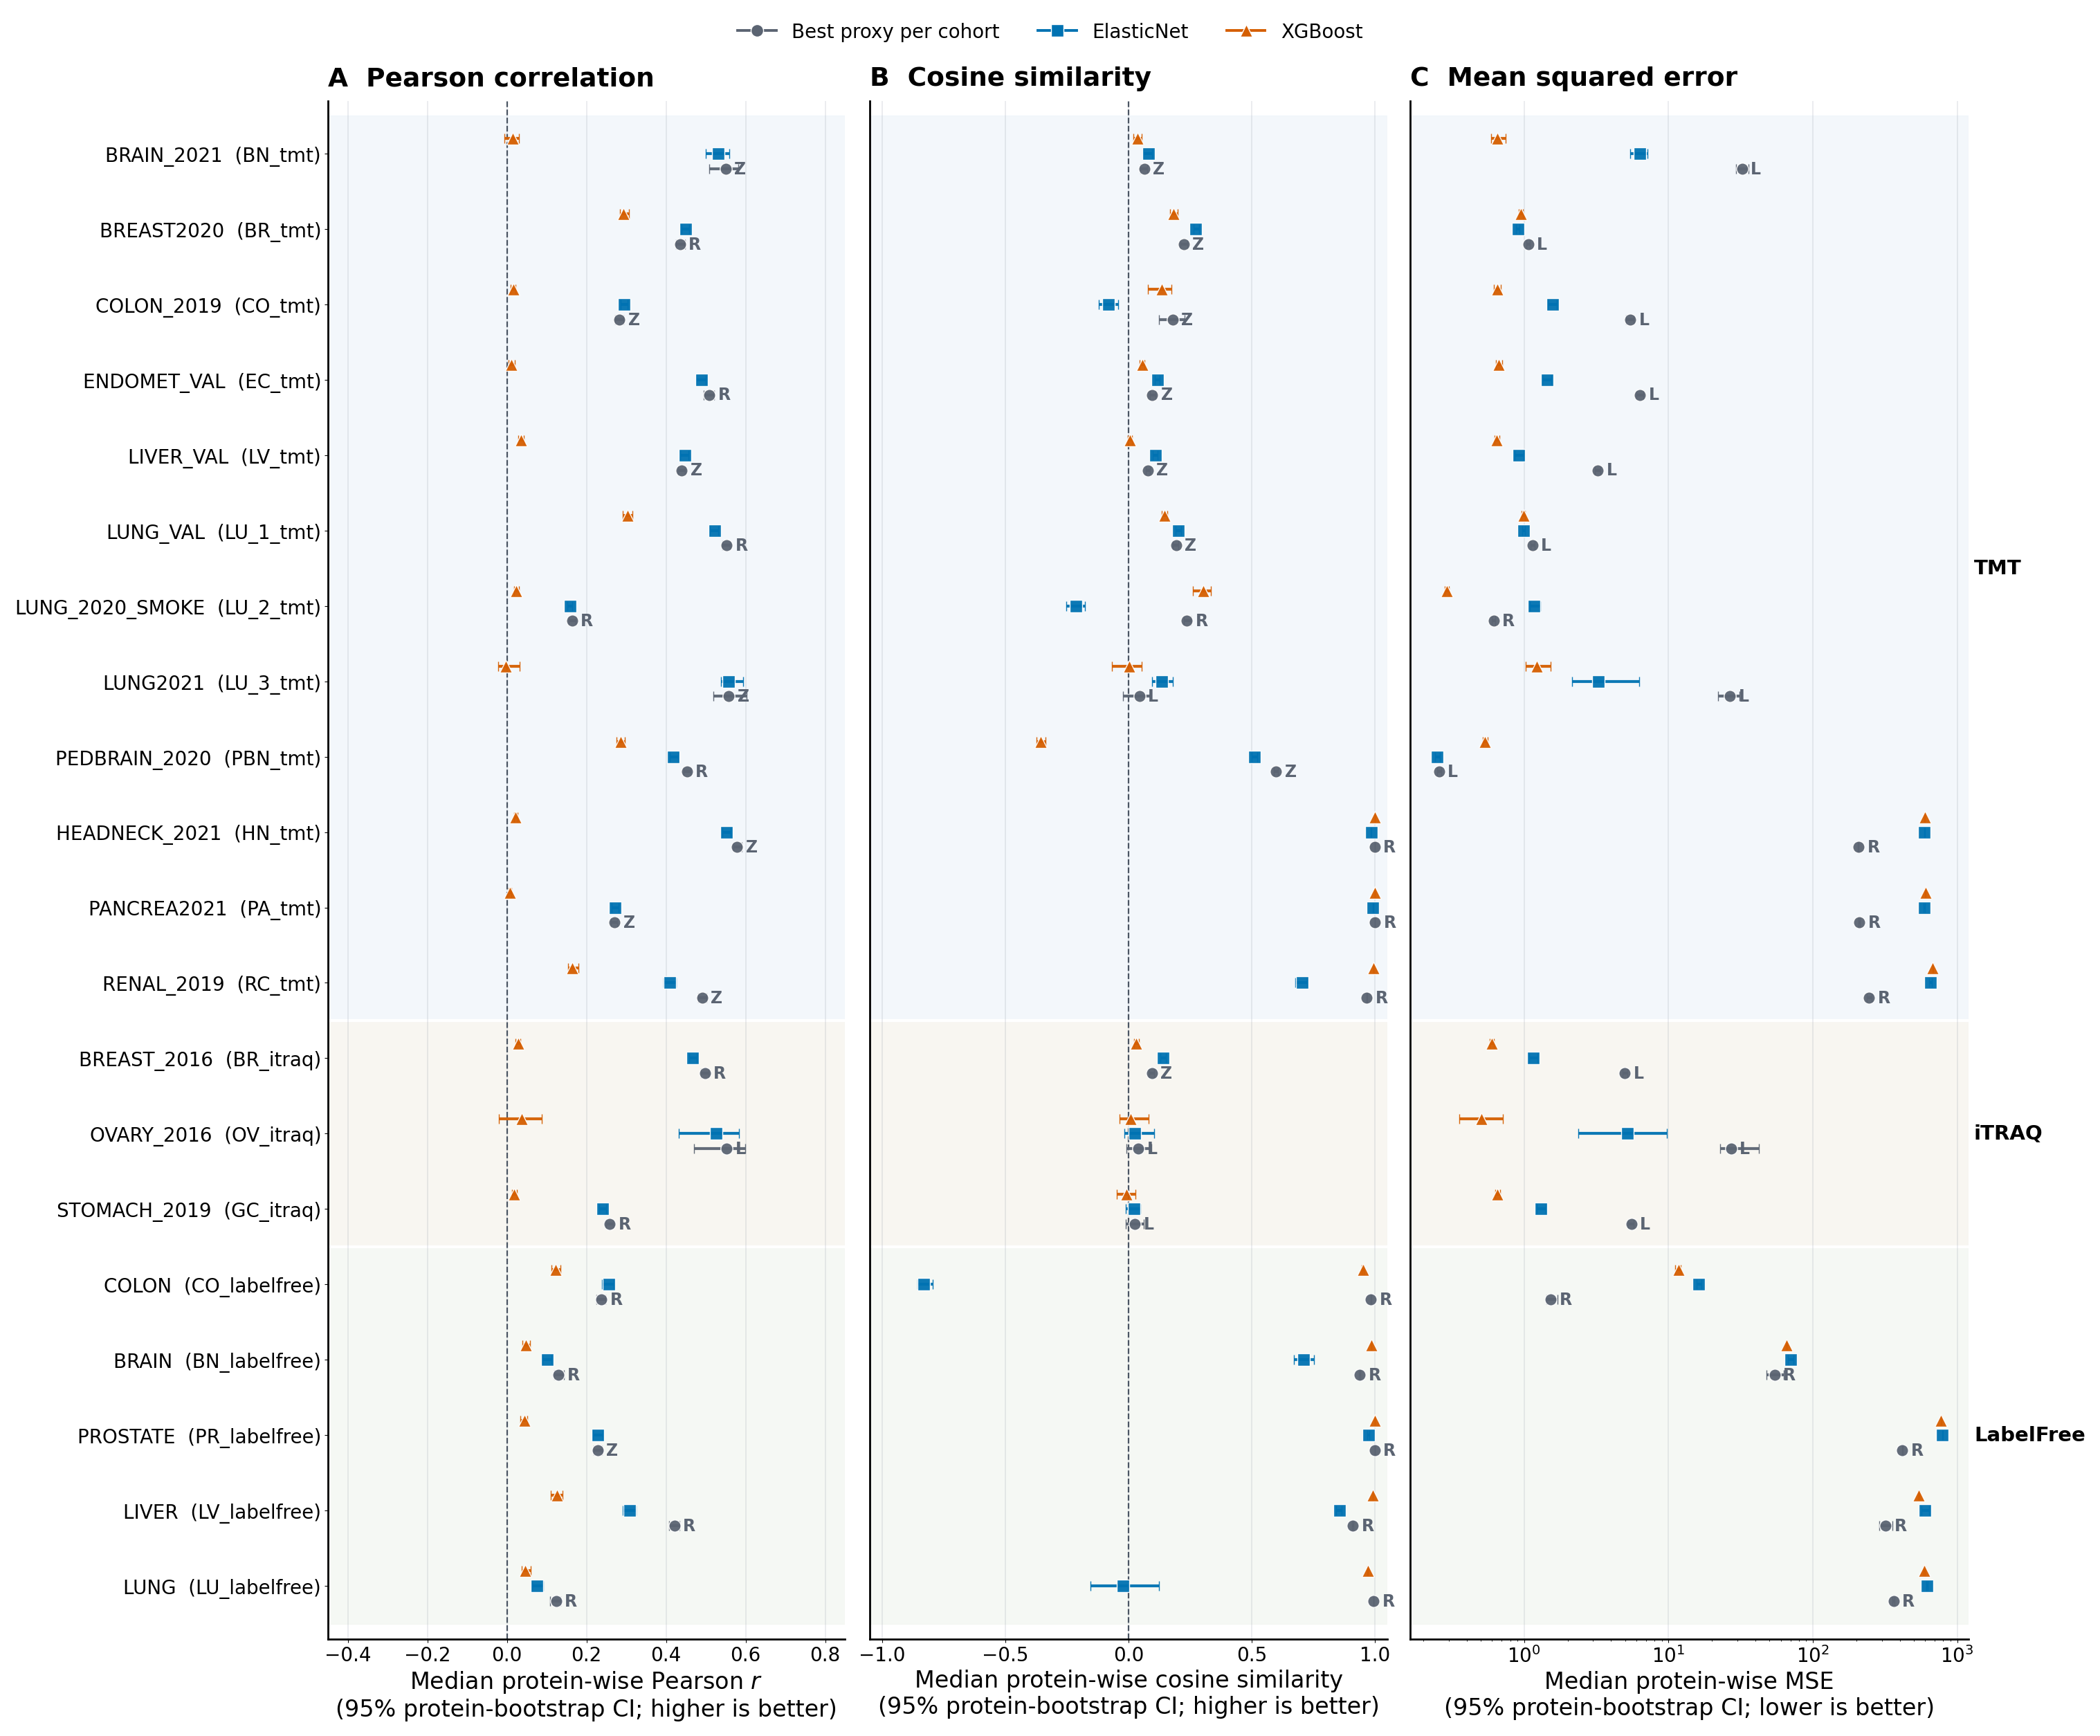

In [20]:
figure_paths = []

fig, axes = plt.subplots(
    1, 3, figsize=(30.0, 24.0), sharey=True,
    gridspec_kw={"width_ratios": [1.0, 1.0, 1.08]}, constrained_layout=True,
)
_metric_axis(
    axes[0], "pearson", data=metric_ci_best_proxy_by_cohort,
    model_order=COHORT_BEST_MODEL_ORDER, model_labels=COHORT_BEST_MODEL_LABEL,
    model_styles=COHORT_BEST_MODEL_STYLE, show_ylabels=True,
    title="A  Pearson correlation", annotate_cohort_proxy=True,
)
_metric_axis(
    axes[1], "cosine", data=metric_ci_best_proxy_by_cohort,
    model_order=COHORT_BEST_MODEL_ORDER, model_labels=COHORT_BEST_MODEL_LABEL,
    model_styles=COHORT_BEST_MODEL_STYLE, show_ylabels=False,
    title="B  Cosine similarity", annotate_cohort_proxy=True,
)
_metric_axis(
    axes[2], "mse", data=metric_ci_best_proxy_by_cohort,
    model_order=COHORT_BEST_MODEL_ORDER, model_labels=COHORT_BEST_MODEL_LABEL,
    model_styles=COHORT_BEST_MODEL_STYLE, show_ylabels=False,
    title="C  Mean squared error", platform_labels=True, annotate_cohort_proxy=True,
)

fig.legend(
    handles=cohort_best_legend_handles, loc="upper center", bbox_to_anchor=(0.50, 1.035),
    ncol=3, frameon=False,
)
figure_paths += _save_figure(
    fig, "figure_external_validation_primary",
    title="External transfer with best same-gene proxy selected per cohort",
)
plt.show()


## 5. Per-protein best-proxy grid

This second 1x3 grid is intentionally more optimistic. For each cohort, protein, and metric, the best of Raw, Z-score, and Linear proxy is selected first; these selected per-protein values are then summarized by their cohort median and protein-bootstrap interval. ElasticNet and XGBoost remain frozen. The exact winning proxy for every protein is exported in `external_proxy_best_per_protein_metric`.


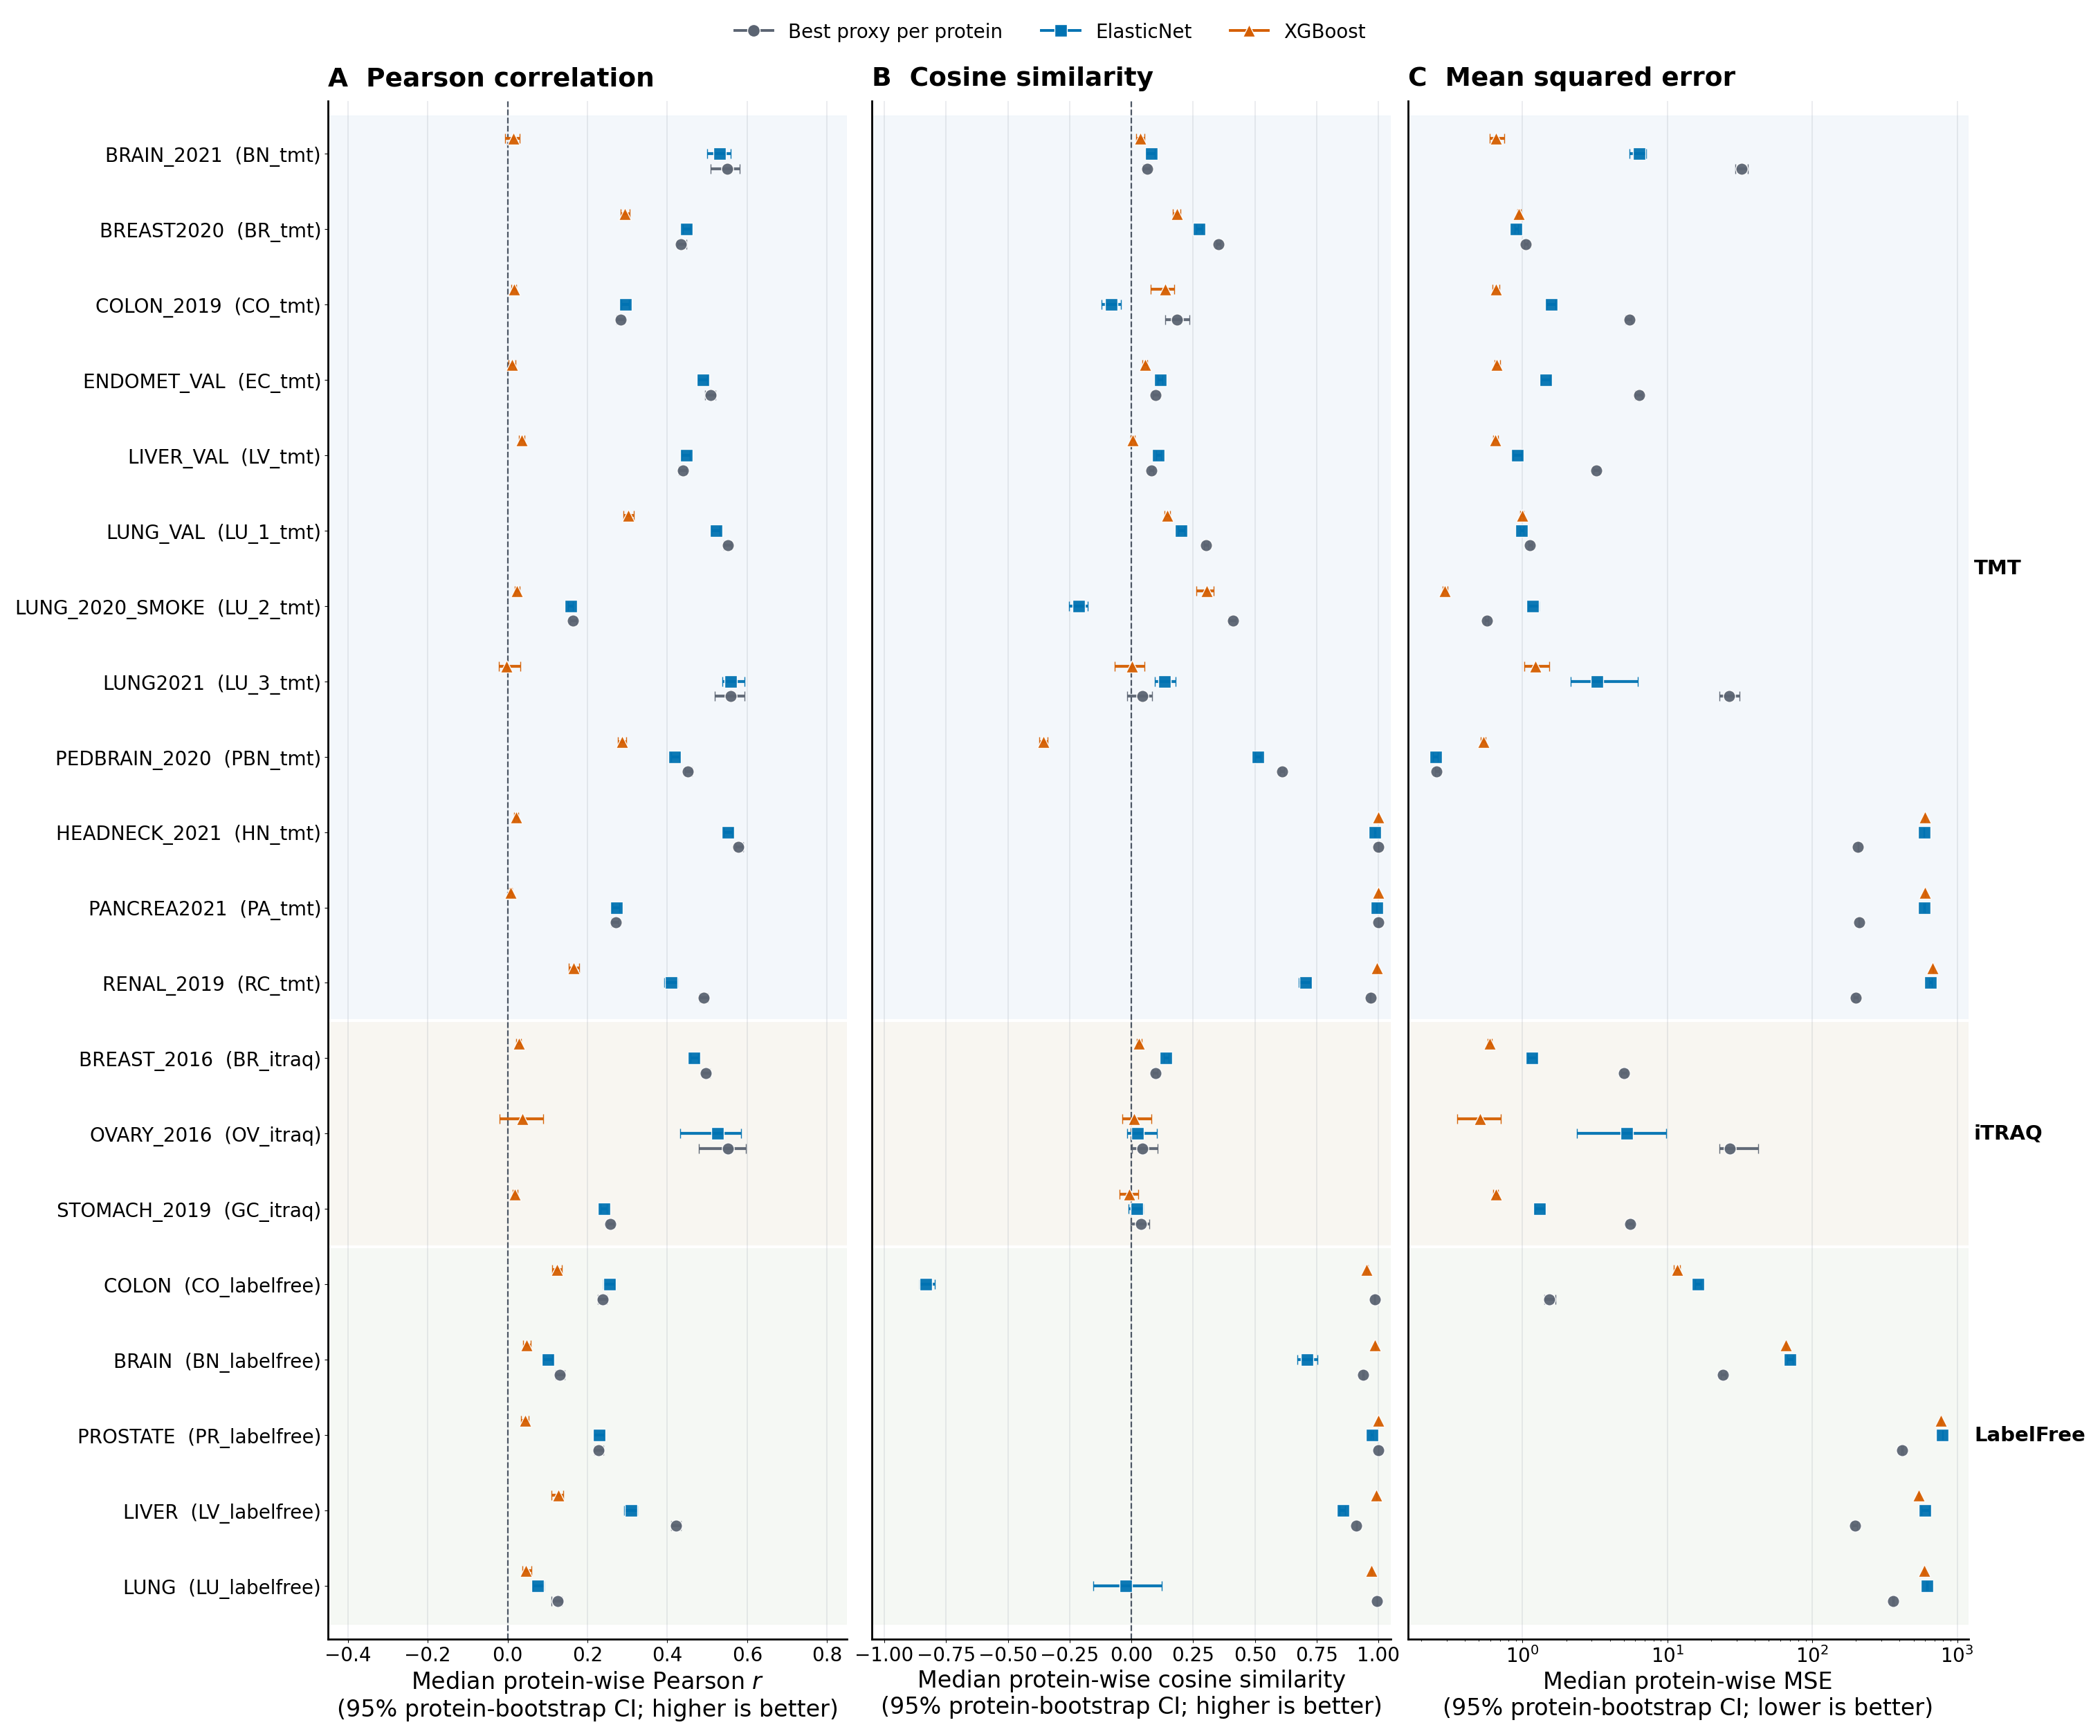

selected_proxy_model,cohort,metric,RawProxy,ZscoreProxy,LinearProxy
0,BRAIN,cosine,0.998450,0.000000,0.001550
1,BRAIN,mse,0.440083,0.107438,0.452479
2,BRAIN,pearson,0.272727,0.369318,0.357955
3,BRAIN_2021,cosine,0.034335,0.324034,0.641631
4,BRAIN_2021,mse,0.000000,0.000000,1.000000
5,BRAIN_2021,pearson,0.270386,0.351931,0.377682
6,BREAST2020,cosine,0.403163,0.375709,0.221128
7,BREAST2020,mse,0.011041,0.106834,0.882125
8,BREAST2020,pearson,0.263802,0.333035,0.403163
9,BREAST_2016,cosine,0.026396,0.330092,0.643512


In [21]:
fig, axes = plt.subplots(
    1, 3, figsize=(30.0, 24.0), sharey=True,
    gridspec_kw={"width_ratios": [1.0, 1.0, 1.08]}, constrained_layout=True,
)
_metric_axis(
    axes[0], "pearson", data=metric_ci_best_proxy_per_protein,
    model_order=PROTEIN_BEST_MODEL_ORDER, model_labels=PROTEIN_BEST_MODEL_LABEL,
    model_styles=PROTEIN_BEST_MODEL_STYLE, show_ylabels=True,
    title="A  Pearson correlation",
)
_metric_axis(
    axes[1], "cosine", data=metric_ci_best_proxy_per_protein,
    model_order=PROTEIN_BEST_MODEL_ORDER, model_labels=PROTEIN_BEST_MODEL_LABEL,
    model_styles=PROTEIN_BEST_MODEL_STYLE, show_ylabels=False,
    title="B  Cosine similarity",
)
_metric_axis(
    axes[2], "mse", data=metric_ci_best_proxy_per_protein,
    model_order=PROTEIN_BEST_MODEL_ORDER, model_labels=PROTEIN_BEST_MODEL_LABEL,
    model_styles=PROTEIN_BEST_MODEL_STYLE, show_ylabels=False,
    title="C  Mean squared error", platform_labels=True,
)
fig.legend(
    handles=protein_best_legend_handles, loc="upper center", bbox_to_anchor=(0.50, 1.035),
    ncol=3, frameon=False,
)
figure_paths += _save_figure(
    fig, "figure_external_metrics_best_proxy_per_protein_grid",
    title="External transfer with best same-gene proxy selected per protein and metric",
)
plt.show()

# Compact selection-frequency audit: how often each proxy wins at protein level.
selection_share = (
    proxy_best_per_protein_choice_summary
    .pivot_table(
        index=["cohort", "metric"], columns="selected_proxy_model",
        values="selection_fraction", fill_value=0, aggfunc="sum", observed=True,
    )
    .reindex(columns=PROXY_VARIANT_ORDER, fill_value=0)
    .reset_index()
)
paths["proxy_best_per_protein_selection_share"] = pv.write_table(
    selection_share, LAYOUT["tables"] / "external_proxy_best_per_protein_selection_share", index=False
)
display(selection_share)


## 6. Platform-level fixed-primary-model summary

This secondary figure remains based on the **frozen primary models** (LinearProxy, ElasticNet, XGBoost), because normalized RMSE is available in notebook-7 primary outputs but is not reconstructed for all three auxiliary proxy variants. It is therefore kept separate from the best-proxy upper-envelope figures above.


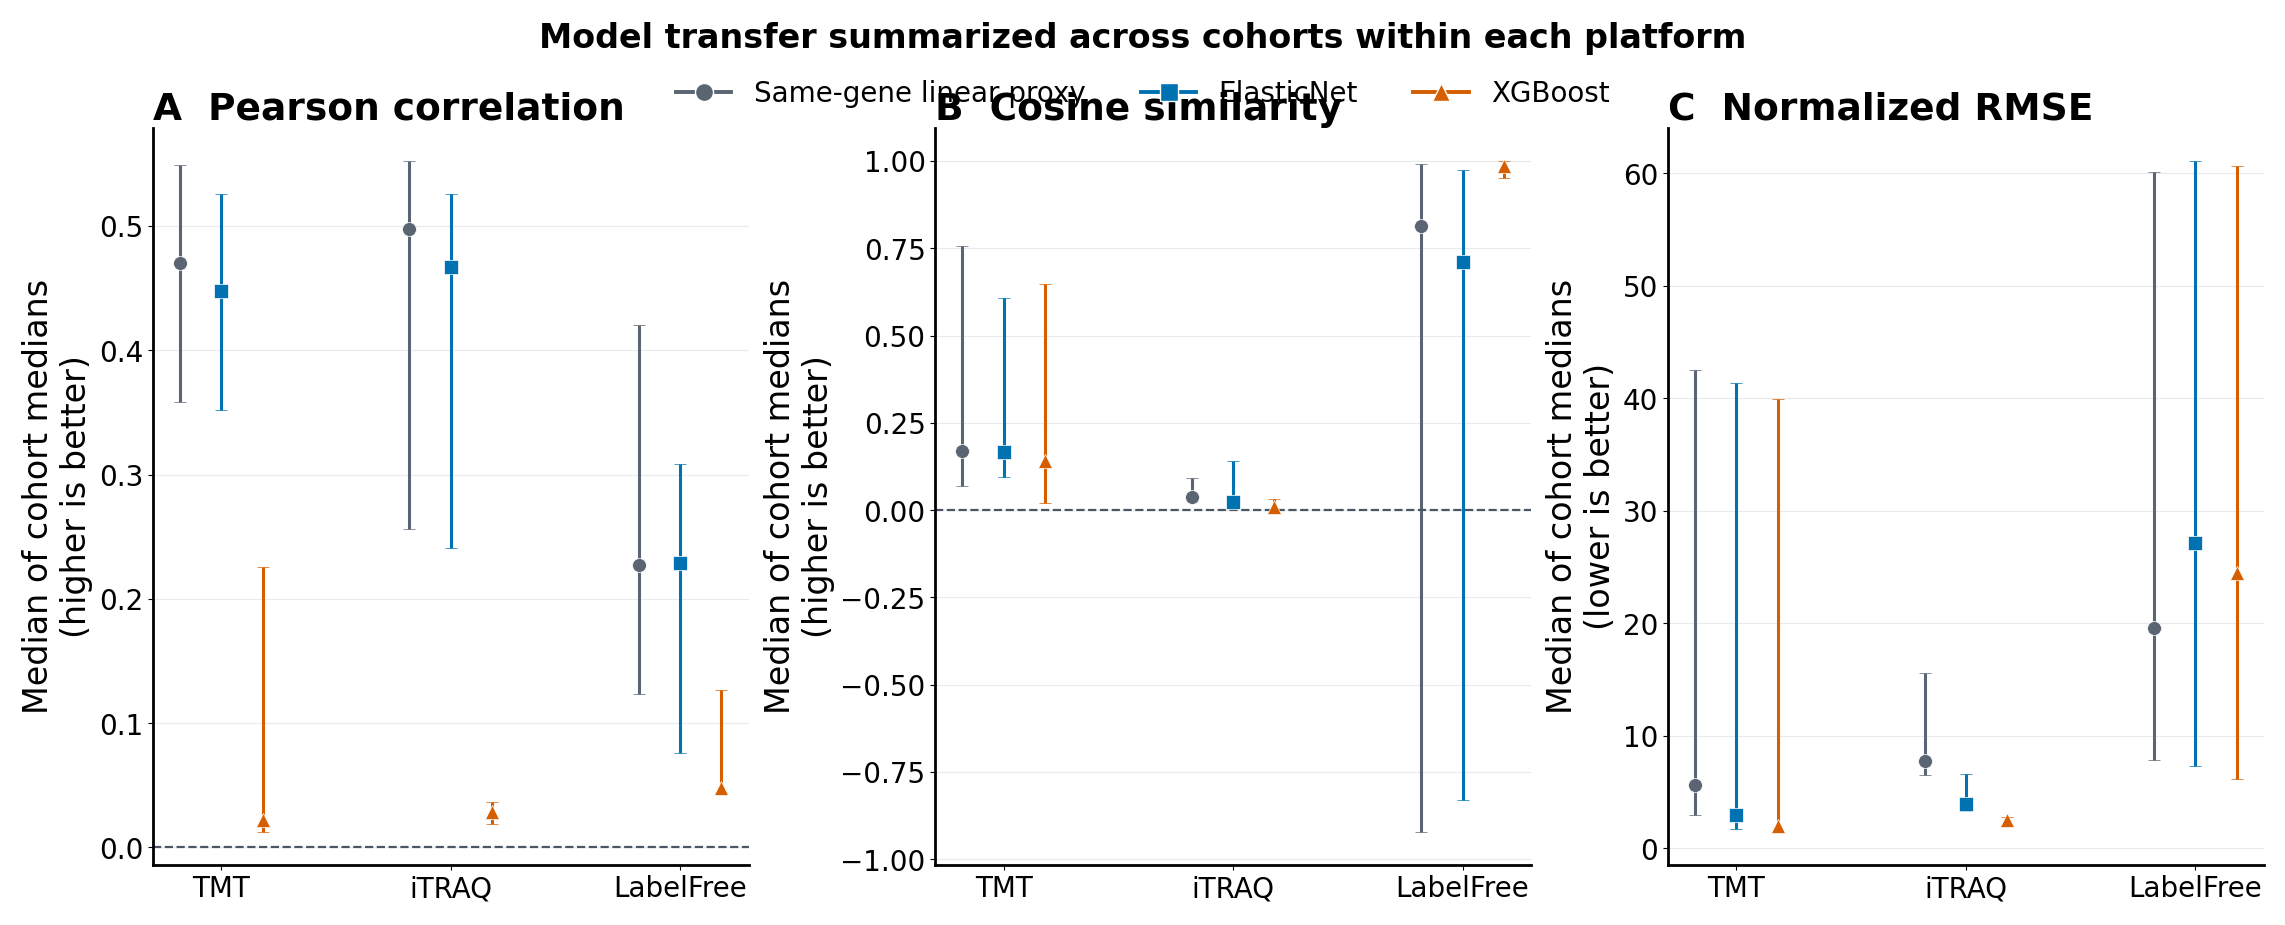

,manifest_hash,platform,model,metric,metric_label,direction,cohorts,median_of_cohort_medians,ci_low,ci_high
0,98cdc5451b903c1769428a4757a2859815a411310b36ef...,TMT,LinearProxy,pearson,Pearson $r$,higher,12,0.470055,0.358658,0.549268
1,98cdc5451b903c1769428a4757a2859815a411310b36ef...,TMT,LinearProxy,cosine,Cosine similarity,higher,12,0.170655,0.068903,0.756929
2,98cdc5451b903c1769428a4757a2859815a411310b36ef...,TMT,LinearProxy,normalized_rmse,Normalized RMSE,lower,12,5.642016,2.951156,42.524853
3,98cdc5451b903c1769428a4757a2859815a411310b36ef...,TMT,ElasticNet,pearson,Pearson $r$,higher,12,0.447998,0.352077,0.525985
4,98cdc5451b903c1769428a4757a2859815a411310b36ef...,TMT,ElasticNet,cosine,Cosine similarity,higher,12,0.167401,0.095413,0.607842
5,98cdc5451b903c1769428a4757a2859815a411310b36ef...,TMT,ElasticNet,normalized_rmse,Normalized RMSE,lower,12,2.978594,1.689563,41.369968
6,98cdc5451b903c1769428a4757a2859815a411310b36ef...,TMT,XGBoost,pearson,Pearson $r$,higher,12,0.022278,0.012630,0.225403
7,98cdc5451b903c1769428a4757a2859815a411310b36ef...,TMT,XGBoost,cosine,Cosine similarity,higher,12,0.140561,0.020974,0.648761
8,98cdc5451b903c1769428a4757a2859815a411310b36ef...,TMT,XGBoost,normalized_rmse,Normalized RMSE,lower,12,1.975259,1.485811,39.969140
9,98cdc5451b903c1769428a4757a2859815a411310b36ef...,iTRAQ,LinearProxy,pearson,Pearson $r$,higher,3,0.497228,0.256265,0.552148


In [22]:
platform_rows = []
platform_metric_map = {
    "pearson": ("Pearson $r$", "higher"),
    "cosine": ("Cosine similarity", "higher"),
    "normalized_rmse": ("Normalized RMSE", "lower"),
}
for platform in PLATFORM_ORDER:
    for model in FIXED_MODEL_ORDER:
        for metric, (label, direction) in platform_metric_map.items():
            vals = metric_ci.loc[
                metric_ci["platform"].eq(platform)
                & metric_ci["model"].eq(model)
                & metric_ci["metric"].eq(metric),
                "median"
            ]
            point, low, high = pv.bootstrap_stat_ci(
                vals, statistic="median", repetitions=PLOT_BOOTSTRAPS,
                seed=PLOT_SEED + pv.stable_int(f"platform|{platform}|{model}|{metric}"),
            )
            platform_rows.append({
                "manifest_hash": MANIFEST_HASH,
                "platform": platform,
                "model": model,
                "metric": metric,
                "metric_label": label,
                "direction": direction,
                "cohorts": int(pd.to_numeric(vals, errors="coerce").notna().sum()),
                "median_of_cohort_medians": point,
                "ci_low": low,
                "ci_high": high,
            })
platform_metric_summary = pd.DataFrame(platform_rows)
paths["platform_metric_summary"] = pv.write_table(
    platform_metric_summary, LAYOUT["tables"] / "external_platform_metric_summary", index=False
)

fig, axes = plt.subplots(1, 3, figsize=(22.5, 8.2), constrained_layout=True)
for ax, metric, title in zip(
    axes,
    ["pearson", "cosine", "normalized_rmse"],
    ["A  Pearson correlation", "B  Cosine similarity", "C  Normalized RMSE"],
):
    sub = platform_metric_summary[platform_metric_summary["metric"].eq(metric)]
    xbase = np.arange(len(PLATFORM_ORDER), dtype=float)
    offsets = {"LinearProxy": -0.18, "ElasticNet": 0.0, "XGBoost": 0.18}
    for model in FIXED_MODEL_ORDER:
        m = sub[sub["model"].eq(model)].set_index("platform").reindex(PLATFORM_ORDER)
        x = xbase + offsets[model]
        y = pd.to_numeric(m["median_of_cohort_medians"], errors="coerce").to_numpy(float)
        lo = pd.to_numeric(m["ci_low"], errors="coerce").to_numpy(float)
        hi = pd.to_numeric(m["ci_high"], errors="coerce").to_numpy(float)
        yerr = np.vstack([np.maximum(0, y-lo), np.maximum(0, hi-y)])
        s = FIXED_MODEL_STYLE[model]
        ax.errorbar(
            x, y, yerr=yerr, fmt=s["marker"], color=s["color"],
            markerfacecolor=s["color"], markeredgecolor="white", markeredgewidth=0.5,
            markersize=10, capsize=4.5, elinewidth=2.2, label=FIXED_MODEL_LABEL[model],
        )
    ax.set_xticks(xbase, PLATFORM_ORDER)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.grid(axis="y", color="#9CA3AF", alpha=0.22)
    if metric in {"pearson", "cosine"}:
        ax.axhline(0, color="#4B5563", linewidth=1.6, linestyle="--")
        ax.set_ylabel("Median of cohort medians\n(higher is better)")
    else:
        ax.set_ylabel("Median of cohort medians\n(lower is better)")

fig.legend(handles=fixed_legend_handles, loc="upper center", bbox_to_anchor=(0.5, 1.04), ncol=3, frameon=False)
fig.suptitle("Model transfer summarized across cohorts within each platform", y=1.08, fontsize=24, fontweight="bold")
figure_paths += _save_figure(
    fig, "figure_external_platform_metric_summary",
    title="Platform-level external validation metric summary",
)
plt.show()
display(platform_metric_summary)


## 7. Secondary diagnostics for the frozen primary model set

Pooled-sample and preprocessing-sensitivity analyses require notebook-7 prediction/scenario outputs and therefore remain tied to the fixed primary LinearProxy, ElasticNet, and XGBoost models. They are not reinterpreted as best-of-three proxy analyses.


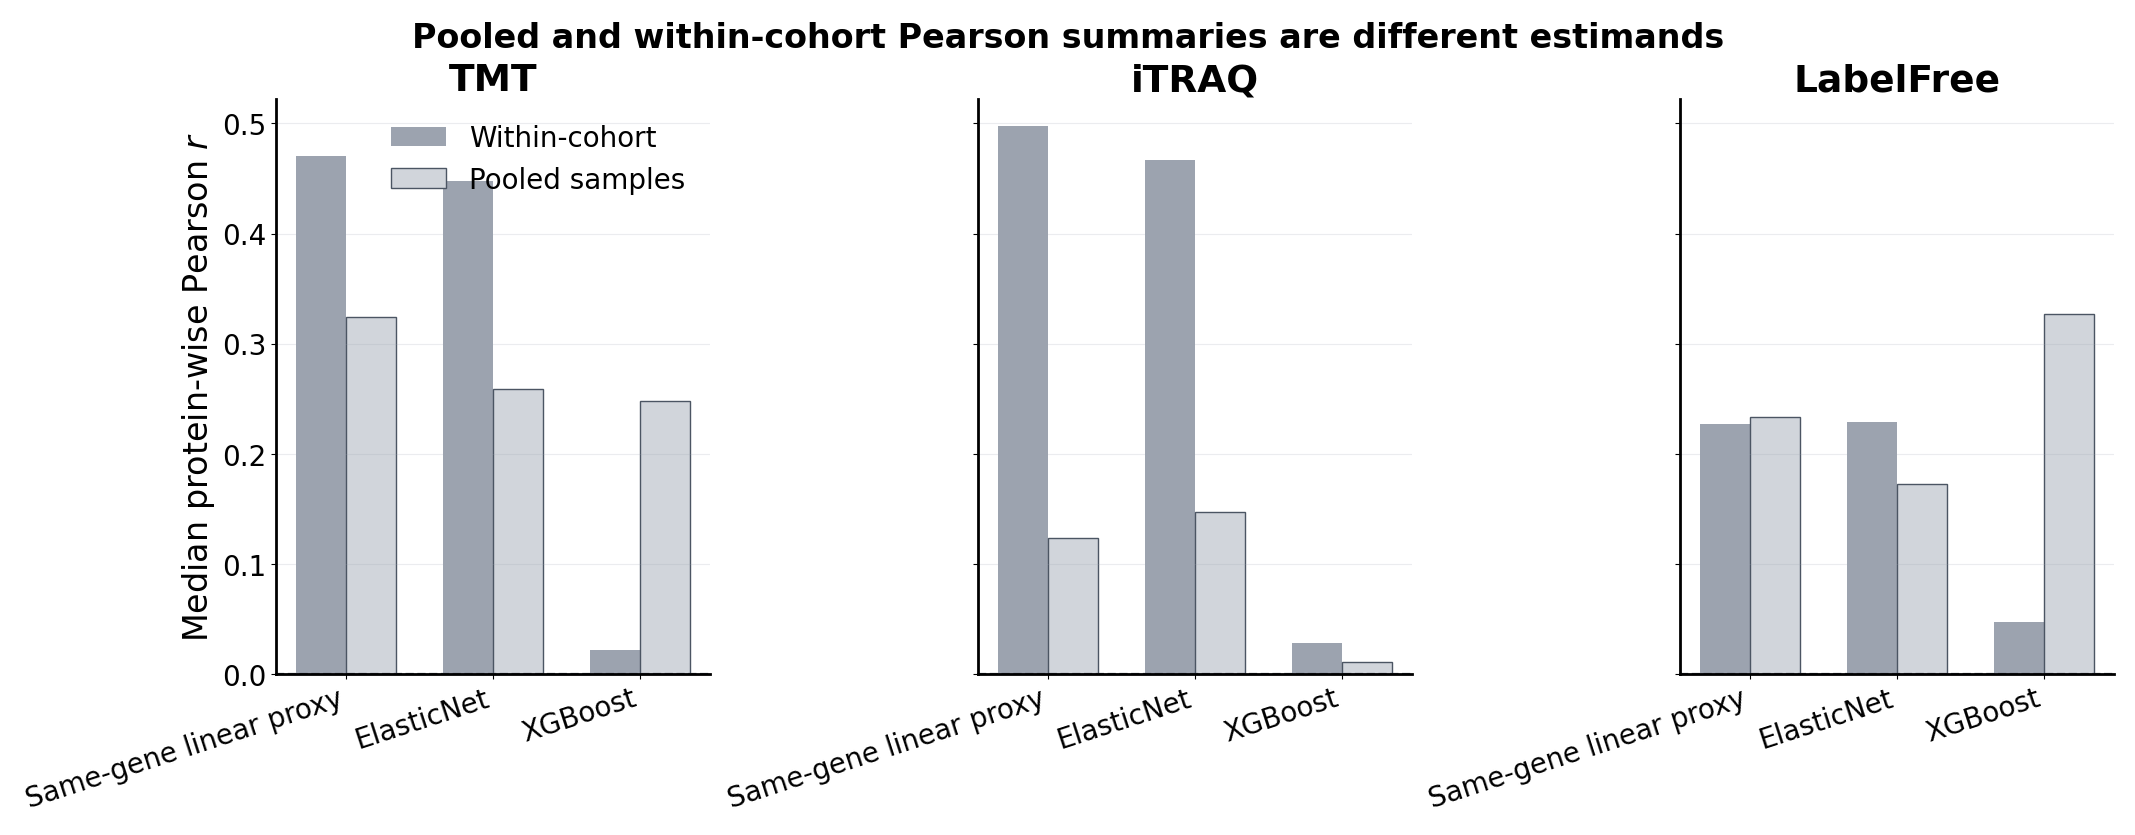

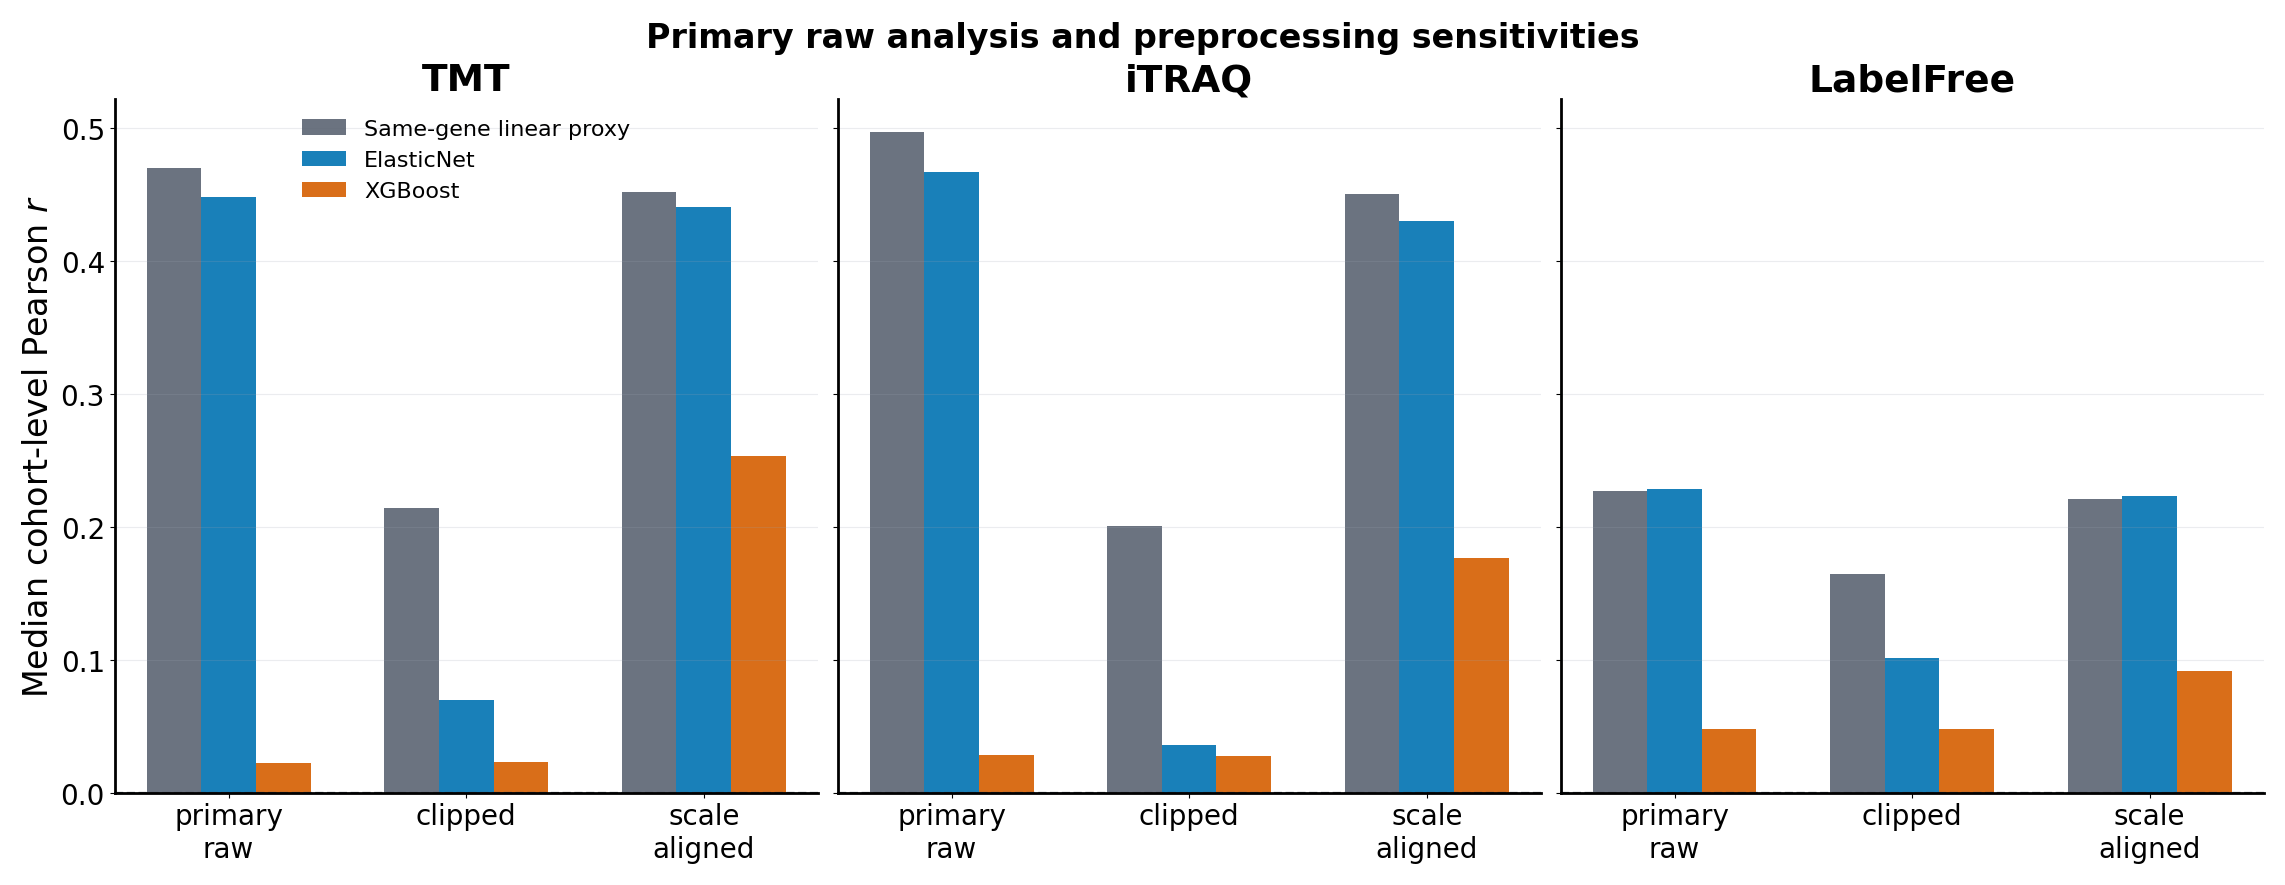

In [23]:
# Pooled versus within-cohort Pearson — deliberately shown as two different estimands.
within_platform = (
    metric_ci.loc[metric_ci["metric"].eq("pearson")]
    .groupby(["platform", "model"], observed=True)["median"]
    .median().rename("within_cohort_median_of_medians").reset_index()
)
compare = within_platform.merge(
    pooled_summary[["platform", "model", "median_pearson"]], on=["platform", "model"], how="inner"
).rename(columns={"median_pearson": "pooled_sample_median"})

fig, axes = plt.subplots(1, 3, figsize=(21.0, 8.0), sharey=True, constrained_layout=True)
for ax, platform in zip(axes, PLATFORM_ORDER):
    sub = compare[compare["platform"].eq(platform)].set_index("model").reindex(FIXED_MODEL_ORDER)
    x = np.arange(len(FIXED_MODEL_ORDER)); width = 0.34
    ax.bar(x - width/2, sub["within_cohort_median_of_medians"], width, color="#9CA3AF", label="Within-cohort")
    ax.bar(x + width/2, sub["pooled_sample_median"], width, color="#D1D5DB", edgecolor="#4B5563", label="Pooled samples")
    ax.set_xticks(x, [FIXED_MODEL_LABEL[m] for m in FIXED_MODEL_ORDER], rotation=18, ha="right")
    ax.set_title(platform, fontweight="bold")
    ax.axhline(0, color="#4B5563", linewidth=1.6, linestyle="--")
    ax.grid(axis="y", color="#9CA3AF", alpha=0.2)
axes[0].set_ylabel("Median protein-wise Pearson $r$")
axes[0].legend(frameon=False)
fig.suptitle("Pooled and within-cohort Pearson summaries are different estimands", fontsize=24, fontweight="bold")
figure_paths += _save_figure(fig, "figure_external_pooled_vs_within", title="Pooled versus within-cohort Pearson")
plt.show()

# Preprocessing sensitivity on the primary matched universe.
sens_platform = (
    sensitivity_summary.groupby(["platform", "scenario", "model"], observed=True)["median_pearson"]
    .median().reset_index()
)
fig, axes = plt.subplots(1, 3, figsize=(22.5, 8.5), sharey=True, constrained_layout=True)
for ax, platform in zip(axes, PLATFORM_ORDER):
    sub = sens_platform[sens_platform["platform"].eq(platform)]
    scenarios = list(pv.SCENARIOS)
    x = np.arange(len(scenarios)); width = 0.23
    for i, model in enumerate(FIXED_MODEL_ORDER):
        vals = sub[sub["model"].eq(model)].set_index("scenario").reindex(scenarios)["median_pearson"]
        s = FIXED_MODEL_STYLE[model]
        ax.bar(x + (i-1)*width, vals, width, color=s["color"], alpha=0.90, label=FIXED_MODEL_LABEL[model])
    ax.set_xticks(x, [s.replace("_", "\n") for s in scenarios], rotation=0)
    ax.set_title(platform, fontweight="bold")
    ax.axhline(0, color="#4B5563", linewidth=1.6, linestyle="--")
    ax.grid(axis="y", color="#9CA3AF", alpha=0.20)
axes[0].set_ylabel("Median cohort-level Pearson $r$")
axes[0].legend(frameon=False, fontsize=16)
fig.suptitle("Primary raw analysis and preprocessing sensitivities", fontsize=24, fontweight="bold")
figure_paths += _save_figure(fig, "figure_external_sensitivity", title="External preprocessing sensitivity")
plt.show()


## 8. Evaluation-universe denominators and cohort-level metric ranking

Universe denominators are unchanged. The compact metric winner table below uses the **best proxy per cohort and metric** together with frozen ElasticNet and XGBoost.


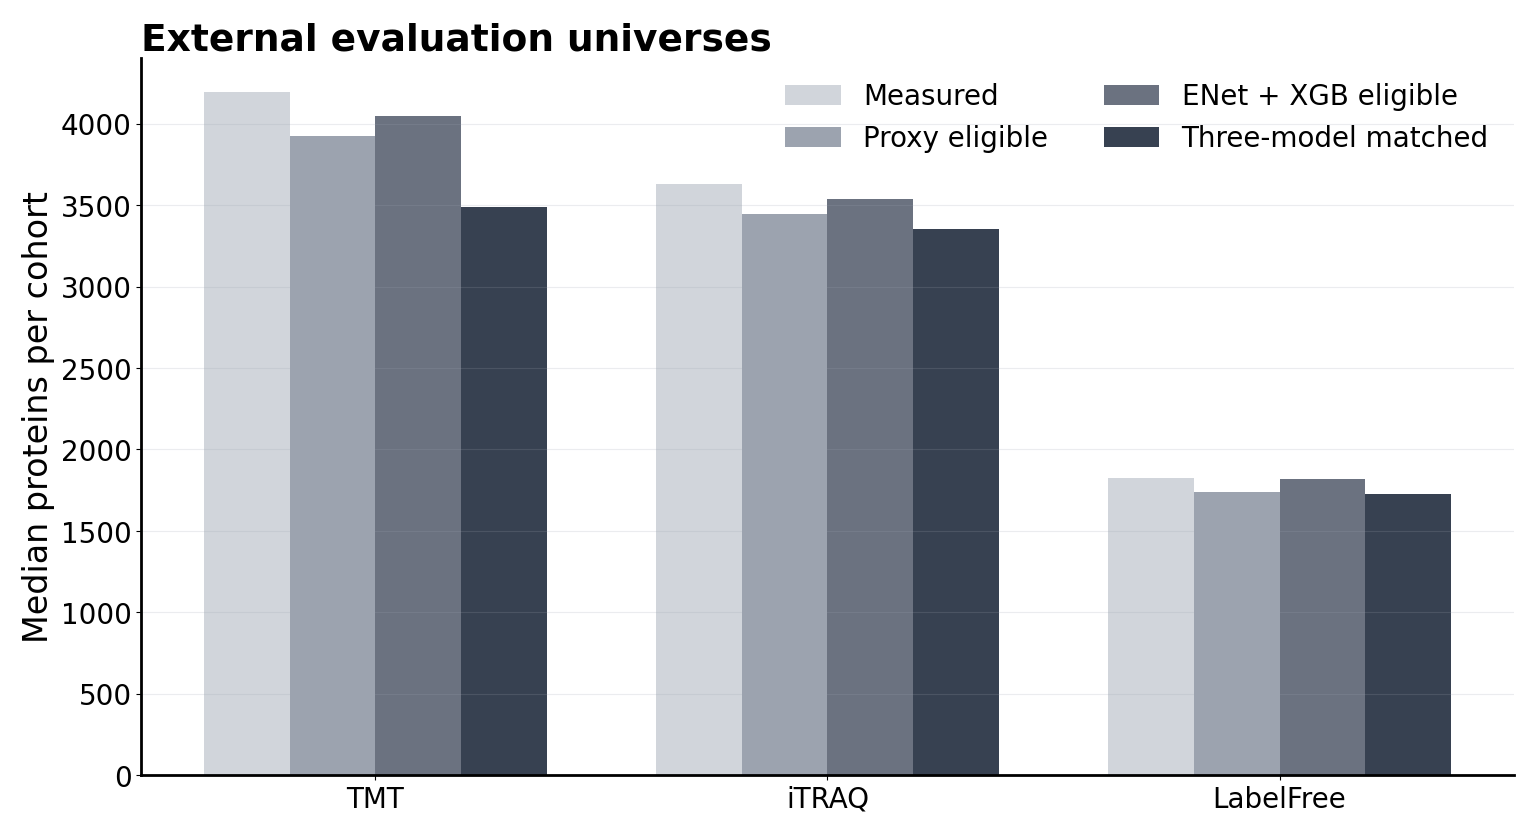

,metric,best_model_by_cohort_median,datasets_best
0,cosine,BestProxyCohort,6
1,cosine,ElasticNet,7
2,cosine,XGBoost,7
3,mse,BestProxyCohort,8
4,mse,ElasticNet,3
5,mse,XGBoost,9
6,pearson,BestProxyCohort,13
7,pearson,ElasticNet,7


In [24]:
counts_platform = universe_counts.groupby("platform", observed=True)[
    ["measurable_proteins", "proxy_eligible", "multigene_eligible", "matched_primary"]
].median().reset_index()

fig, ax = plt.subplots(figsize=(15.0, 8.0), constrained_layout=True)
x = np.arange(len(PLATFORM_ORDER)); width = 0.19
columns = ["measurable_proteins", "proxy_eligible", "multigene_eligible", "matched_primary"]
labels = ["Measured", "Proxy eligible", "ENet + XGB eligible", "Three-model matched"]
greys = ["#D1D5DB", "#9CA3AF", "#6B7280", "#374151"]
for i, (col, label, colour) in enumerate(zip(columns, labels, greys)):
    vals = counts_platform.set_index("platform").reindex(PLATFORM_ORDER)[col]
    ax.bar(x + (i-1.5)*width, vals, width, label=label, color=colour)
ax.set_xticks(x, PLATFORM_ORDER)
ax.set_ylabel("Median proteins per cohort")
ax.set_title("External evaluation universes", loc="left", fontweight="bold")
ax.legend(frameon=False, ncol=2)
ax.grid(axis="y", color="#9CA3AF", alpha=0.20)
figure_paths += _save_figure(fig, "figure_external_universes", title="External evaluation universes")
plt.show()

winner_rows = []
for cohort in DATASET_ORDER:
    for metric in ["pearson", "cosine", "mse"]:
        sub = metric_ci_best_proxy_by_cohort[(metric_ci_best_proxy_by_cohort["cohort"].eq(cohort)) & (metric_ci_best_proxy_by_cohort["metric"].eq(metric))].copy()
        sub = sub[np.isfinite(pd.to_numeric(sub["median"], errors="coerce"))]
        if sub.empty:
            continue
        idx = sub["median"].idxmin() if metric == "mse" else sub["median"].idxmax()
        row = sub.loc[idx]
        winner_rows.append({
            "manifest_hash": MANIFEST_HASH,
            "cohort": cohort,
            "platform": row["platform"],
            "metric": metric,
            "best_model_by_cohort_median": row["model"],
            "best_median": row["median"],
        })
model_ranking = pd.DataFrame(winner_rows)
paths["model_ranking"] = pv.write_table(model_ranking, LAYOUT["tables"] / "external_model_ranking_by_dataset", index=False)

winner_counts = (
    model_ranking.groupby(["metric", "best_model_by_cohort_median"], observed=True)
    .size().rename("datasets_best").reset_index()
)
display(winner_counts)


## 9. Figure registry and provenance


In [25]:
# De-duplicate paths while preserving generation order.
_unique = []
_seen = set()
for p in figure_paths:
    p = Path(p)
    if str(p.resolve()) not in _seen:
        _seen.add(str(p.resolve()))
        _unique.append(p)
figure_paths = _unique


# PDF-only invariant for manuscript figures.
_non_pdf = [p for p in figure_paths if Path(p).suffix.lower() != ".pdf"]
if _non_pdf:
    raise RuntimeError(f"Notebook 08 produced non-PDF figure paths: {_non_pdf}")
_missing = [p for p in figure_paths if not Path(p).exists()]
if _missing:
    raise RuntimeError(f"Notebook 08 figure files are missing: {_missing}")

figure_registry = pd.DataFrame([{
    "manifest_hash": MANIFEST_HASH,
    "figure": path.name,
    "format": path.suffix.lower().lstrip("."),
    "path": str(path.resolve()),
    "sha256": pv.file_sha256(path),
} for path in figure_paths])
paths["figure_registry"] = pv.write_table(
    figure_registry, FIGURE_PDF_DIR / "figure_registry", index=False
)

provenance = pv.notebook_provenance(
    "08_plots_paper_ready_best_proxy_per_tissue_and_protein.ipynb",
    MANIFEST_HASH,
    {"completion_status_directory": str(LAYOUT["evaluation_status"].resolve())},
    {key: str(Path(value).resolve()) for key, value in paths.items()} | {
        "plot_directory": str(FIGURE_PDF_DIR.resolve())
    },
)
pv.atomic_json_dump(provenance, FIGURE_PDF_DIR / "notebook08_provenance.json")

print(f"Registered {len(figure_registry)} figure files.")
print("All tables and figures were regenerated from one internally consistent frozen notebook-7 result run; best-proxy upper envelopes are explicitly exported and audited.")
print("Frozen result manifest hash:", MANIFEST_HASH)
print("Current validation manifest hash:", CURRENT_MANIFEST_HASH)
print("Manifest hashes match:", MANIFEST_MATCHES_CURRENT)
display(figure_registry)


Registered 6 figure files.
All tables and figures were regenerated from one internally consistent frozen notebook-7 result run; best-proxy upper envelopes are explicitly exported and audited.
Frozen result manifest hash: 98cdc5451b903c1769428a4757a2859815a411310b36efcb7ddbbf347f2bce50
Current validation manifest hash: 98cdc5451b903c1769428a4757a2859815a411310b36efcb7ddbbf347f2bce50
Manifest hashes match: True


,manifest_hash,figure,format,path,sha256
0,98cdc5451b903c1769428a4757a2859815a411310b36ef...,figure_external_validation_primary.pdf,pdf,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,8fcc8a0420fe205ba50777ee73cffd36da3813e8d1d8b0...
1,98cdc5451b903c1769428a4757a2859815a411310b36ef...,figure_external_metrics_best_proxy_per_protein...,pdf,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,d441741cbc31642eac33da61f0f1d0c194a376ed610cd3...
2,98cdc5451b903c1769428a4757a2859815a411310b36ef...,figure_external_platform_metric_summary.pdf,pdf,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,ae0ff53a4a8d8b9745d2512b4101a2ec505db3cc75c592...
3,98cdc5451b903c1769428a4757a2859815a411310b36ef...,figure_external_pooled_vs_within.pdf,pdf,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,7d37454ae568cf1b60361ef634a5e0200b7390566f5db2...
4,98cdc5451b903c1769428a4757a2859815a411310b36ef...,figure_external_sensitivity.pdf,pdf,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,afd5caa7b8e75b933da4208dbbb488ef128f6fe0015384...
5,98cdc5451b903c1769428a4757a2859815a411310b36ef...,figure_external_universes.pdf,pdf,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,4be6da283fb04effe2e86bd57d4539cc97b1d1708e487d...
